# ðŸ—ï¸ PrÃ©traitement Intelligent des DonnÃ©es â€” PrÃ©diction Score de Risque Chantier

**Auteur :** Expert IA & GÃ©nie Civil  
**Date :** Avril 2026  
**Contexte :** Safety-First & IA â€” Cahier des charges GC

---

## ðŸ“‹ Structure du notebook

| Section | Contenu |
|---------|---------|
| **0** | Configuration & Imports |
| **1** | Analyse Exploratoire Intelligente (EDA + cohÃ©rence GC) |
| **2** | PrÃ©traitement NumÃ©rique (NaN, Outliers, Scaling) |
| **3** | NLP AvancÃ© (Regex, Lexique GC, TF-IDF / CamemBERT) |
| **4** | Fusion Texte + NumÃ©rique |
| **5** | SÃ©lection des Variables (CorrÃ©lation + RF + VIF) |
| **6** | Lacunes & Recommandations |
| **7** | Export + Pipeline sklearn |

> âš ï¸ **Principe directeur :** *aucun traitement sans justification mÃ©tier*. Chaque dÃ©cision est expliquÃ©e scientifiquement ET par la rÃ©alitÃ© du terrain GC.

## Section 0 â€” Configuration & Imports

Les librairies `spaCy` et `transformers` sont **optionnelles** (fallback automatique vers NLTK + TF-IDF si absentes). Tous les autres packages sont disponibles dans l'environnement `.venv`.

In [1]:
# â”€â”€ 0.1 Imports â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats

# Scikit-learn
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from statsmodels.stats.outliers_influence import variance_inflation_factor

# NLP
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords as nltk_sw

# spaCy â€” optionnel
try:
    import spacy
    NLP_FR = spacy.load('fr_core_news_md')
    SPACY_OK = True
    print('âœ“ spaCy fr_core_news_md chargÃ©')
except Exception as _e:
    SPACY_OK = False
    print(f'âš  spaCy absent ({_e}) â†’ fallback NLTK')

# Transformers â€” optionnel
try:
    from transformers import AutoTokenizer, AutoModel
    import torch
    BERT_OK = True
    print('âœ“ Transformers / PyTorch disponibles')
except Exception as _e:
    BERT_OK = False
    print(f'âš  Transformers absent ({_e}) â†’ fallback TF-IDF')

warnings.filterwarnings('ignore')

# â”€â”€ 0.2 Constantes globales â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH   = 'Dataset.csv'
OUTPUT_PATH = 'processed_dataset.csv'

NUM_COLS  = ['Effectif', 'Temperature', 'Vent_kmh', 'EPI_Manquants', 'Risque_Historique']
CAT_COLS  = ['Type_Travaux']
TEXT_COL  = 'Rapport_inspection'
TARGET    = 'Score_Risque'
ID_COL    = 'ID_Inspection'

# â”€â”€ Seuils mÃ©tier GC (rÃ©glementaires) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
GC_THRESHOLDS = {
    'Vent_kmh'      : {'alerte': 45, 'danger': 80, 'impossible': 250},
    'Temperature'   : {'min_possible': -30, 'max_possible': 60,
                       'alerte_froid': 5, 'alerte_chaleur': 35},
    'EPI_Manquants' : {'critique': 5, 'max_possible': 15},
    'Effectif'      : {'surveillance': 30, 'max_possible': 200},
    'Risque_Historique': {'min': 0.0, 'max': 1.0},
}

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
print(f'\nâœ… Configuration chargÃ©e â€” RANDOM_STATE={RANDOM_STATE}')
print(f'   Dataset : {DATA_PATH}')


ModuleNotFoundError: No module named 'statsmodels'

---
## Section 1 â€” Analyse Exploratoire Intelligente

> **Approche expert GC :** avant tout prÃ©traitement, on valide la *cohÃ©rence physique* des donnÃ©es. Un capteur dÃ©faillant sur chantier peut injecter des valeurs aberrantes qui corrompent silencieusement le modÃ¨le.

In [ ]:
# â”€â”€ 1.1 Chargement & inspection brute â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
df_raw = pd.read_csv(DATA_PATH)
print(f'Dimensions : {df_raw.shape[0]} lignes Ã— {df_raw.shape[1]} colonnes\n')
print('Types de colonnes :')
print(df_raw.dtypes.to_string())
df_raw.head()


Dimensions : 1000 lignes Ã— 9 colonnes

Types de colonnes :
ID_Inspection             str
Type_Travaux              str
Effectif              float64
Temperature           float64
Vent_kmh              float64
EPI_Manquants         float64
Risque_Historique     float64
Score_Risque          float64
Rapport_inspection        str


,ID_Inspection,Type_Travaux,Effectif,Temperature,Vent_kmh,EPI_Manquants,Risque_Historique,Score_Risque,Rapport_inspection
0,INS-001,Travail en Hauteur,NaN,NaN,46.0,7.0,0.77,NaN,Rapport d'inspection â€” Travail en Hauteur. Con...
1,INS-002,Excavation,30.0,4.0,33.0,4.0,0.00,100.0,Fiche d'inspection terrain â€” Excavation. Au mo...
2,INS-003,Excavation,NaN,27.0,64.0,NaN,0.86,NaN,Fiche d'inspection terrain â€” Excavation. Les c...
3,INS-004,Coffrage,44.0,NaN,54.0,7.0,0.19,NaN,Compte rendu de visite de sÃ©curitÃ© â€” chantier ...
4,INS-005,NaN,NaN,7.0,NaN,1.0,0.55,88.0,Compte rendu de visite de sÃ©curitÃ© â€” chantier ...


=== Taux de valeurs manquantes (%) ===
Effectif         35.6
Vent_kmh         35.0
Type_Travaux     34.7
Score_Risque     34.2
Temperature      33.6
EPI_Manquants    32.8


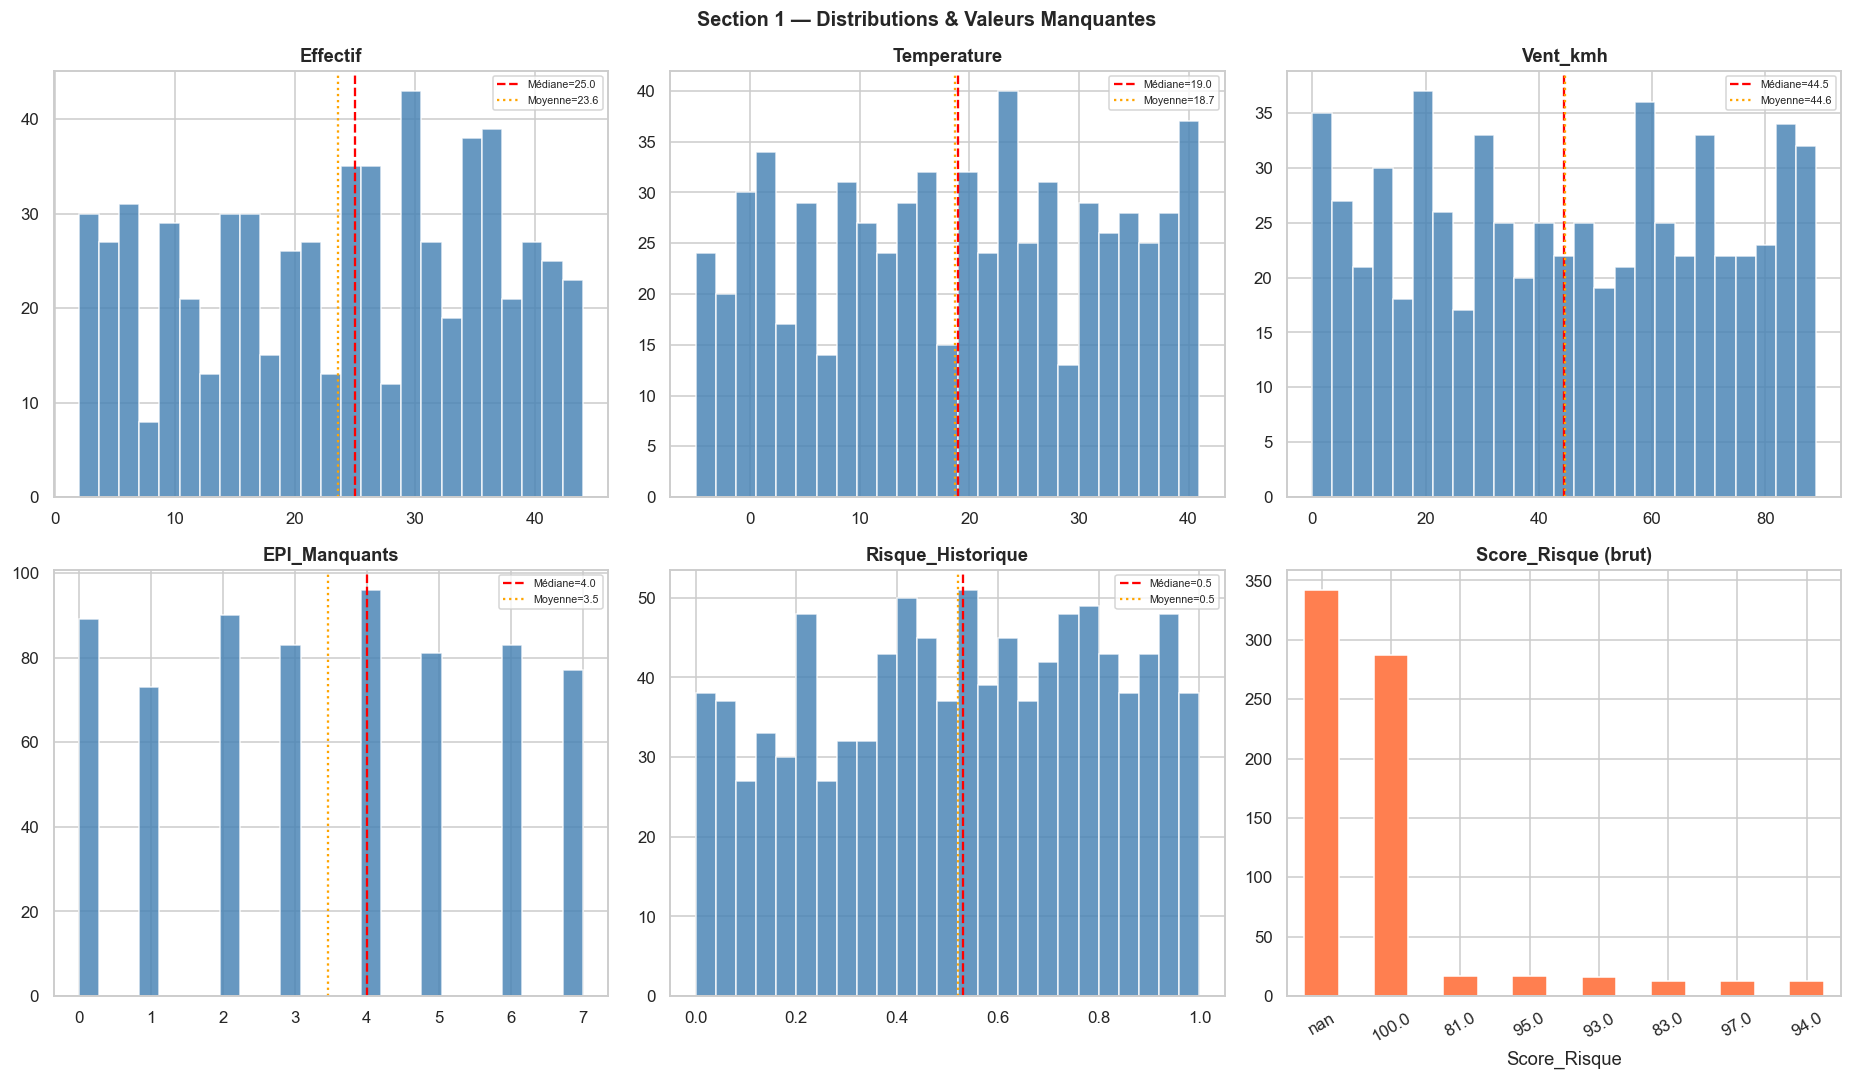

In [ ]:
# â”€â”€ 1.2 Distribution des variables + taux de NaN â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
for c in NUM_COLS:
    df_raw[c] = pd.to_numeric(df_raw[c], errors='coerce')

missing = df_raw.isnull().mean().mul(100).round(1)
print('=== Taux de valeurs manquantes (%) ===')
print(missing[missing > 0].sort_values(ascending=False).to_string())

fig = plt.figure(figsize=(17, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig)

for i, col in enumerate(NUM_COLS):
    ax = fig.add_subplot(gs[0, i % 3] if i < 3 else gs[1, i - 3])
    data = df_raw[col].dropna()
    ax.hist(data, bins=25, color='steelblue', edgecolor='white', alpha=0.82)
    ax.axvline(data.median(), color='red', ls='--', lw=1.5, label=f'MÃ©diane={data.median():.1f}')
    ax.axvline(data.mean(),   color='orange', ls=':', lw=1.5, label=f'Moyenne={data.mean():.1f}')
    ax.set_title(col, fontweight='bold')
    ax.legend(fontsize=7)

ax_t = fig.add_subplot(gs[1, 2])
df_raw[TARGET].value_counts(dropna=False).head(8).plot.bar(ax=ax_t, color='coral', edgecolor='white')
ax_t.set_title('Score_Risque (brut)', fontweight='bold')
ax_t.tick_params(axis='x', rotation=30)

fig.suptitle('Section 1 â€” Distributions & Valeurs Manquantes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# â”€â”€ 1.3 ContrÃ´les de cohÃ©rence mÃ©tier GC (valeurs physiquement impossibles) â”€â”€
print('=' * 65)
print('  CONTRÃ”LES DE COHÃ‰RENCE MÃ‰TIER (domaine GÃ©nie Civil)')
print('=' * 65)

anomalies = []

# TempÃ©rature
t_mask = df_raw['Temperature'].dropna()
impossible_temp = t_mask[(t_mask < GC_THRESHOLDS['Temperature']['min_possible']) |
                          (t_mask > GC_THRESHOLDS['Temperature']['max_possible'])]
if len(impossible_temp) > 0:
    anomalies.append(('Temperature', len(impossible_temp), 'Valeur hors plage physique [-30Â°C, 60Â°C]', 'âŒ ERREUR CAPTEUR'))
    print(f'[Temperature] {len(impossible_temp)} valeurs impossibles : {impossible_temp.values}')
else:
    print('[Temperature] âœ“ Toutes valeurs dans plage physique [-30Â°C, 60Â°C]')

# Vent
v_mask = df_raw['Vent_kmh'].dropna()
impossible_vent = v_mask[v_mask > GC_THRESHOLDS['Vent_kmh']['impossible']]
vent_danger     = v_mask[(v_mask > GC_THRESHOLDS['Vent_kmh']['danger']) &
                          (v_mask <= GC_THRESHOLDS['Vent_kmh']['impossible'])]
if len(impossible_vent) > 0:
    anomalies.append(('Vent_kmh', len(impossible_vent), f'> {GC_THRESHOLDS["Vent_kmh"]["impossible"]} km/h = impossible', 'âŒ ERREUR CAPTEUR'))
    print(f'[Vent_kmh   ] {len(impossible_vent)} valeurs impossibles (>{GC_THRESHOLDS["Vent_kmh"]["impossible"]} km/h)')
print(f'[Vent_kmh   ] {len(vent_danger)} valeurs danger rÃ©el (>{GC_THRESHOLDS["Vent_kmh"]["danger"]} km/h) â†’ âš  CONSERVER')

# EPI
epi_mask = df_raw['EPI_Manquants'].dropna()
impossible_epi = epi_mask[(epi_mask < 0) | (epi_mask > GC_THRESHOLDS['EPI_Manquants']['max_possible'])]
if len(impossible_epi) > 0:
    anomalies.append(('EPI_Manquants', len(impossible_epi), f'Valeur hors [0, {GC_THRESHOLDS["EPI_Manquants"]["max_possible"]}]', 'âŒ ERREUR SAISIE'))
    print(f'[EPI_Manquants] {len(impossible_epi)} valeurs impossibles')
else:
    print(f'[EPI_Manquants] âœ“ Plage valide (0â€“{GC_THRESHOLDS["EPI_Manquants"]["max_possible"]})')

# Effectif
eff_mask = df_raw['Effectif'].dropna()
impossible_eff = eff_mask[(eff_mask < 0) | (eff_mask > GC_THRESHOLDS['Effectif']['max_possible'])]
if len(impossible_eff) > 0:
    anomalies.append(('Effectif', len(impossible_eff), 'Effectif nÃ©gatif ou > 200', 'âŒ ERREUR SAISIE'))
    print(f'[Effectif   ] {len(impossible_eff)} valeurs impossibles')
else:
    print(f'[Effectif   ] âœ“ Plage valide (0â€“{GC_THRESHOLDS["Effectif"]["max_possible"]})')

# Risque_Historique
rh_mask = df_raw['Risque_Historique'].dropna()
bad_rh = rh_mask[(rh_mask < 0) | (rh_mask > 1)]
if len(bad_rh) > 0:
    anomalies.append(('Risque_Historique', len(bad_rh), 'Hors [0, 1]', 'âŒ ERREUR'))
    print(f'[Risque_Hist] {len(bad_rh)} valeurs hors [0,1]')
else:
    print(f'[Risque_Hist] âœ“ Plage valide [0, 1]')

print('\n=== Rapport des anomalies physiques ===')
if anomalies:
    print(pd.DataFrame(anomalies, columns=['Variable','N','ProblÃ¨me','Type']).to_string(index=False))
else:
    print('âœ… Aucune valeur physiquement impossible dÃ©tectÃ©e.')
print(f'\nâš  Note mÃ©tier : les valeurs extrÃªmes RÃ‰ELLES (ex. Vent=90km/h) seront')
print('  CONSERVÃ‰ES car elles encodent des situations de danger critique sur chantier.')


  CONTRÃ”LES DE COHÃ‰RENCE MÃ‰TIER (domaine GÃ©nie Civil)
[Temperature] âœ“ Toutes valeurs dans plage physique [-30Â°C, 60Â°C]
[Vent_kmh   ] 77 valeurs danger rÃ©el (>80 km/h) â†’ âš  CONSERVER
[EPI_Manquants] âœ“ Plage valide (0â€“15)
[Effectif   ] âœ“ Plage valide (0â€“200)
[Risque_Hist] âœ“ Plage valide [0, 1]

=== Rapport des anomalies physiques ===
âœ… Aucune valeur physiquement impossible dÃ©tectÃ©e.

âš  Note mÃ©tier : les valeurs extrÃªmes RÃ‰ELLES (ex. Vent=90km/h) seront
  CONSERVÃ‰ES car elles encodent des situations de danger critique sur chantier.


In [ ]:
# â”€â”€ 1.4 Analyse de cohÃ©rence Texte â†” NumÃ©rique â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
df_check = df_raw.copy()

def detect_text_risk_level(text):
    """Extrait le niveau de risque mentionnÃ© dans le texte."""
    if not isinstance(text, str):
        return None
    t = text.lower()
    if any(k in t for k in ['critique', 'arrÃªt immÃ©diat', 'danger immÃ©diat']): return 'Critique'
    if any(k in t for k in ['Ã©levÃ©', 'eleve', 'urgente', 'intervention corrective']): return 'Ã‰levÃ©'
    if any(k in t for k in ['modÃ©rÃ©', 'moyen', 'prÃ©ventives']): return 'Moyen'
    if any(k in t for k in ['faible', 'satisfaisant']): return 'Faible'
    return None

df_check['risk_from_text']   = df_check[TEXT_COL].apply(detect_text_risk_level)
df_check['epi_high_numeric'] = df_check['EPI_Manquants'].fillna(0) > 5
df_check['vent_danger']      = df_check['Vent_kmh'].fillna(0) > GC_THRESHOLDS['Vent_kmh']['alerte']

suspects = df_check[(df_check['risk_from_text'] == 'Faible') & (df_check['epi_high_numeric'])]
print(f'IncohÃ©rences texte "Faible" â†” EPI_Manquants > 5 : {len(suspects)} cas')

suspects2 = df_check[(df_check['risk_from_text'] == 'Faible') & (df_check['vent_danger'])]
print(f'IncohÃ©rences texte "Faible" â†” Vent > {GC_THRESHOLDS["Vent_kmh"]["alerte"]} km/h : {len(suspects2)} cas')

total_incoherence = len(suspects) + len(suspects2)
print(f'\nTotal incohÃ©rences texte â†” numÃ©rique : {total_incoherence}')
print('â†’ Ces cas seront gÃ©rÃ©s via la prioritÃ© : score numÃ©rique > texte > heuristique')


IncohÃ©rences texte "Faible" â†” EPI_Manquants > 5 : 12 cas
IncohÃ©rences texte "Faible" â†” Vent > 45 km/h : 25 cas

Total incohÃ©rences texte â†” numÃ©rique : 37
â†’ Ces cas seront gÃ©rÃ©s via la prioritÃ© : score numÃ©rique > texte > heuristique


---
## Section 2 â€” PrÃ©traitement des Variables NumÃ©riques

### 2.1 StratÃ©gie de gestion des NaN â€” justifiÃ©e par variable

| Variable | MÃ©thode | Justification GC |
|----------|---------|-----------------|
| **Temperature** | MÃ©diane | DonnÃ©es mÃ©tÃ©o asymÃ©triques ; la mÃ©diane est robuste aux pics saisonniers |
| **Vent_kmh** | MÃ©diane | MÃªme raison ; prÃ©server les valeurs extrÃªmes rÃ©elles |
| **EPI_Manquants** | 0 si NaN isolÃ©, mÃ©diane sinon | NaN probable = visite rapide sans anomalie notable â†’ 0 EPI |
| **Effectif** | MÃ©diane | Effectif varie peu â†’ mÃ©diane reprÃ©sentative |
| **Risque_Historique** | MÃ©diane | Score continu 0â€“1 ; mÃ©diane prÃ©serve la distribution |

> **Principe :** on ne supprime AUCUNE ligne. Chaque inspection est une donnÃ©e prÃ©cieuse pour la sÃ©curitÃ©.

In [ ]:
# â”€â”€ 2.1 Imputation intelligente â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
df = df_raw.copy()

print('NaN avant imputation :')
print(df[NUM_COLS].isnull().sum().rename('NaN_count').to_string())
print()

df_imp = df[NUM_COLS].copy()

# EPI_Manquants : 0 si NaN (hypothÃ¨se : pas mentionnÃ© = pas de manque constatÃ©)
epi_nan_pct = df_imp['EPI_Manquants'].isna().mean()
if epi_nan_pct < 0.20:
    df_imp['EPI_Manquants'] = df_imp['EPI_Manquants'].fillna(0)
    print(f'EPI_Manquants : NaN â†’ 0 (taux {epi_nan_pct*100:.1f}% < 20%, hypothÃ¨se "absence = conforme")')
else:
    df_imp['EPI_Manquants'] = df_imp['EPI_Manquants'].fillna(df_imp['EPI_Manquants'].median())
    print(f'EPI_Manquants : NaN â†’ mÃ©diane (taux {epi_nan_pct*100:.1f}% â‰¥ 20%, mÃ©diane plus sÃ»re)')

# Toutes les autres â†’ mÃ©diane
for col in [c for c in NUM_COLS if c != 'EPI_Manquants']:
    median_val = df_imp[col].median()
    n_nan = df_imp[col].isna().sum()
    df_imp[col] = df_imp[col].fillna(median_val)
    print(f'{col:<22s}: {n_nan} NaN â†’ mÃ©diane = {median_val:.3f}')

print(f'\nNaN rÃ©siduels : {df_imp.isnull().sum().sum()}')
df[NUM_COLS] = df_imp.values


NaN avant imputation :
Effectif             356
Temperature          336
Vent_kmh             350
EPI_Manquants        328
Risque_Historique      0

EPI_Manquants : NaN â†’ mÃ©diane (taux 32.8% â‰¥ 20%, mÃ©diane plus sÃ»re)
Effectif              : 356 NaN â†’ mÃ©diane = 25.000
Temperature           : 336 NaN â†’ mÃ©diane = 19.000
Vent_kmh              : 350 NaN â†’ mÃ©diane = 44.500
Risque_Historique     : 0 NaN â†’ mÃ©diane = 0.530

NaN rÃ©siduels : 0


  DÃ‰TECTION DES OUTLIERS â€” IQR + Z-score + Isolation Forest

âš  DISTINCTION FONDAMENTALE (contexte GC) :
  âœ… Outlier rÃ©el = situation dangereuse â†’ CONSERVER + crÃ©er flag
  âŒ Outlier = erreur capteur/saisie â†’ CORRIGER/REMPLACER



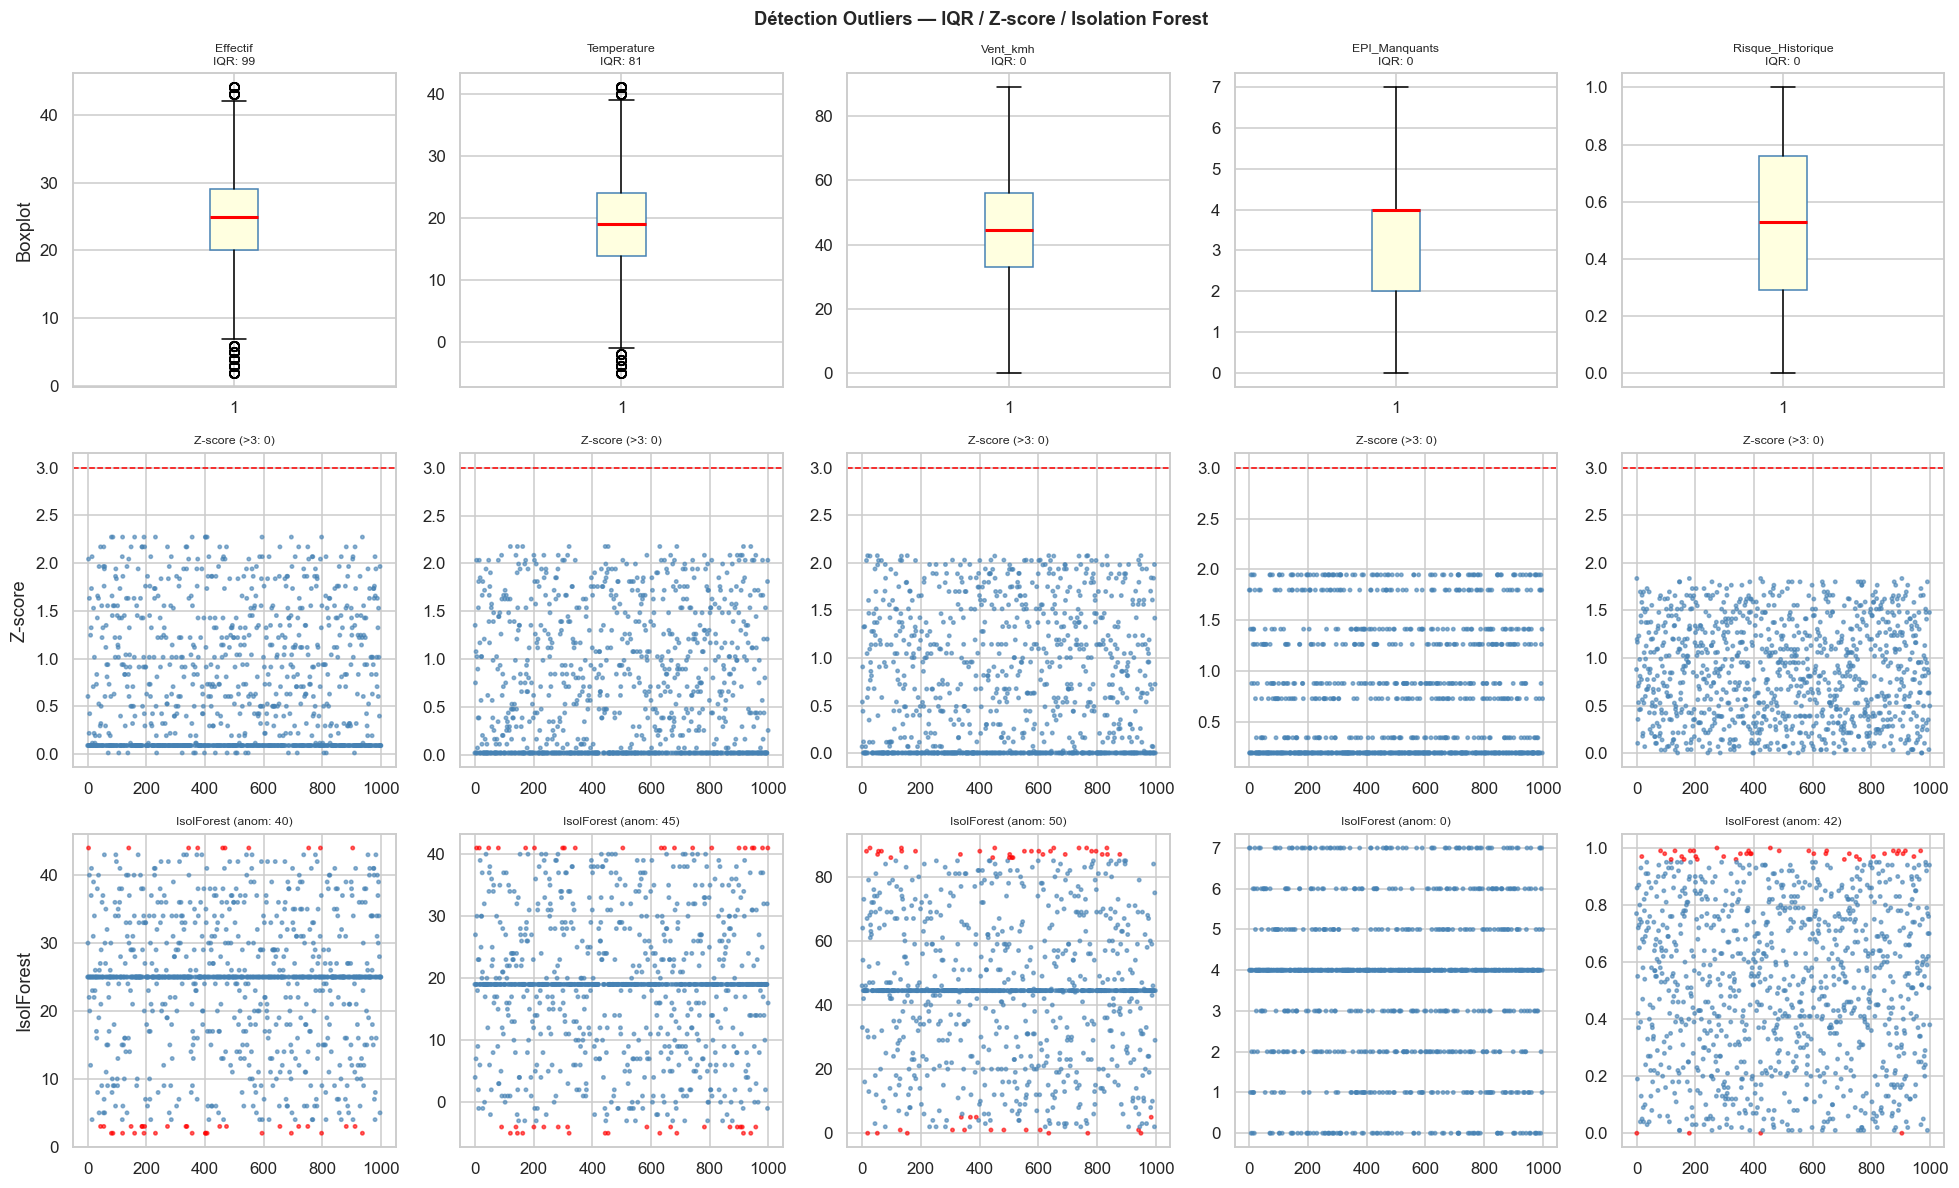


=== Rapport Outliers ===
         Variable  IQR  Z-score  IsolForest  Consensus(â‰¥2)  Lb_IQR  Ub_IQR
         Effectif   99        0          40             40    6.50   42.50
      Temperature   81        0          45             45   -1.62   39.38
         Vent_kmh    0        0          50              0   -1.50   90.50
    EPI_Manquants    0        0           0              0   -1.00    7.00
Risque_Historique    0        0          42              0   -0.42    1.46


In [ ]:
# â”€â”€ 2.2 DÃ©tection des Outliers â€” 3 mÃ©thodes combinÃ©es â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=' * 65)
print('  DÃ‰TECTION DES OUTLIERS â€” IQR + Z-score + Isolation Forest')
print('=' * 65)
print()
print('âš  DISTINCTION FONDAMENTALE (contexte GC) :')
print('  âœ… Outlier rÃ©el = situation dangereuse â†’ CONSERVER + crÃ©er flag')
print('  âŒ Outlier = erreur capteur/saisie â†’ CORRIGER/REMPLACER')
print()

outlier_report = []
fig, axes = plt.subplots(3, len(NUM_COLS), figsize=(18, 11))

for i, col in enumerate(NUM_COLS):
    data = df[col]

    # MÃ©thode 1 : IQR
    Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
    IQR    = Q3 - Q1
    lb_iqr = Q1 - 1.5 * IQR
    ub_iqr = Q3 + 1.5 * IQR
    mask_iqr = (data < lb_iqr) | (data > ub_iqr)

    # MÃ©thode 2 : Z-score
    z_scores = np.abs(stats.zscore(data))
    mask_z   = z_scores > 3

    # MÃ©thode 3 : Isolation Forest
    iso = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
    iso_pred = iso.fit_predict(data.values.reshape(-1, 1))
    mask_iso = iso_pred == -1

    n_iqr  = mask_iqr.sum()
    n_z    = mask_z.sum()
    n_iso  = mask_iso.sum()
    n_consensus = (mask_iqr.astype(int) + mask_z.astype(int) + mask_iso.astype(int) >= 2).sum()

    outlier_report.append({
        'Variable': col, 'IQR': n_iqr, 'Z-score': n_z,
        'IsolForest': n_iso, 'Consensus(â‰¥2)': n_consensus,
        'Lb_IQR': round(lb_iqr, 2), 'Ub_IQR': round(ub_iqr, 2)
    })

    axes[0, i].boxplot(data, patch_artist=True,
                       boxprops=dict(facecolor='lightyellow', color='steelblue'),
                       medianprops=dict(color='red', lw=2))
    axes[0, i].set_title(f'{col}\nIQR: {n_iqr}', fontsize=8)

    axes[1, i].scatter(range(len(z_scores)), z_scores,
                       c=['red' if z > 3 else 'steelblue' for z in z_scores],
                       s=5, alpha=0.6)
    axes[1, i].axhline(3, color='red', ls='--', lw=1)
    axes[1, i].set_title(f'Z-score (>3: {n_z})', fontsize=8)

    colors_iso = ['red' if p == -1 else 'steelblue' for p in iso_pred]
    axes[2, i].scatter(range(len(data)), data, c=colors_iso, s=5, alpha=0.6)
    axes[2, i].set_title(f'IsolForest (anom: {n_iso})', fontsize=8)

axes[0, 0].set_ylabel('Boxplot')
axes[1, 0].set_ylabel('Z-score')
axes[2, 0].set_ylabel('IsolForest')

fig.suptitle('DÃ©tection Outliers â€” IQR / Z-score / Isolation Forest', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

outlier_df = pd.DataFrame(outlier_report)
print('\n=== Rapport Outliers ===')
print(outlier_df.to_string(index=False))


In [ ]:
# â”€â”€ 2.3 Traitement intelligent : erreur vs danger rÃ©el â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
df_clean = df.copy()

# â”€â”€ CrÃ©er features de DANGER (outliers rÃ©els conservÃ©s) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
df_clean['flag_vent_danger']   = (df_clean['Vent_kmh'] > GC_THRESHOLDS['Vent_kmh']['danger']).astype(int)
df_clean['flag_vent_alerte']   = (df_clean['Vent_kmh'].between(GC_THRESHOLDS['Vent_kmh']['alerte'],
                                                                 GC_THRESHOLDS['Vent_kmh']['danger'])).astype(int)
df_clean['flag_temp_froid']    = (df_clean['Temperature'] < GC_THRESHOLDS['Temperature']['alerte_froid']).astype(int)
df_clean['flag_temp_chaleur']  = (df_clean['Temperature'] > GC_THRESHOLDS['Temperature']['alerte_chaleur']).astype(int)
df_clean['flag_epi_critique']  = (df_clean['EPI_Manquants'] >= GC_THRESHOLDS['EPI_Manquants']['critique']).astype(int)
df_clean['flag_effectif_eleve']= (df_clean['Effectif'] > GC_THRESHOLDS['Effectif']['surveillance']).astype(int)

danger_flags = ['flag_vent_danger', 'flag_vent_alerte', 'flag_temp_froid',
                'flag_temp_chaleur', 'flag_epi_critique', 'flag_effectif_eleve']

print('=== Features de DANGER crÃ©Ã©es (outliers rÃ©els conservÃ©s) ===')
for flag in danger_flags:
    pct = df_clean[flag].mean() * 100
    print(f'  {flag:<25s} : {int(df_clean[flag].sum()):>4d} cas ({pct:.1f}%)')

# â”€â”€ Corriger les erreurs capteur (valeurs physiquement impossibles) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
corrections = 0

vent_err = df_clean['Vent_kmh'] > GC_THRESHOLDS['Vent_kmh']['impossible']
if vent_err.sum() > 0:
    df_clean.loc[vent_err, 'Vent_kmh'] = df_clean['Vent_kmh'].median()
    corrections += vent_err.sum()
    print(f'\nâœ— CorrigÃ© {vent_err.sum()} erreurs Vent_kmh > {GC_THRESHOLDS["Vent_kmh"]["impossible"]} km/h â†’ mÃ©diane')

temp_err = ((df_clean['Temperature'] < GC_THRESHOLDS['Temperature']['min_possible']) |
            (df_clean['Temperature'] > GC_THRESHOLDS['Temperature']['max_possible']))
if temp_err.sum() > 0:
    df_clean.loc[temp_err, 'Temperature'] = df_clean['Temperature'].median()
    corrections += temp_err.sum()
    print(f'âœ— CorrigÃ© {temp_err.sum()} erreurs Temperature hors [-30, 60]Â°C â†’ mÃ©diane')

epi_err = df_clean['EPI_Manquants'] > GC_THRESHOLDS['EPI_Manquants']['max_possible']
if epi_err.sum() > 0:
    df_clean.loc[epi_err, 'EPI_Manquants'] = df_clean['EPI_Manquants'].median()
    corrections += epi_err.sum()

# Winsorisation p5â€“p95
df_clean_win = df_clean.copy()
for col in NUM_COLS:
    p5, p95 = df_clean_win[col].quantile([0.05, 0.95])
    df_clean_win[col] = df_clean_win[col].clip(p5, p95)

print(f'\nâœ“ Winsorisation p5â€“p95 appliquÃ©e sur {NUM_COLS}')
print(f'Total corrections erreurs capteur : {corrections}')
print('Justification : winsorisation p5â€“p95 â†’ conserver signaux danger lÃ©gitimes')


=== Features de DANGER crÃ©Ã©es (outliers rÃ©els conservÃ©s) ===
  flag_vent_danger          :   77 cas (7.7%)
  flag_vent_alerte          :  248 cas (24.8%)
  flag_temp_froid           :  125 cas (12.5%)
  flag_temp_chaleur         :   90 cas (9.0%)
  flag_epi_critique         :  241 cas (24.1%)
  flag_effectif_eleve       :  219 cas (21.9%)

âœ“ Winsorisation p5â€“p95 appliquÃ©e sur ['Effectif', 'Temperature', 'Vent_kmh', 'EPI_Manquants', 'Risque_Historique']
Total corrections erreurs capteur : 0
Justification : winsorisation p5â€“p95 â†’ conserver signaux danger lÃ©gitimes


=== Statistiques aprÃ¨s StandardScaler ===
      Effectif_sc  Temperature_sc  Vent_kmh_sc  EPI_Manquants_sc  Risque_Historique_sc
mean       -0.000          -0.000        0.000            -0.000                -0.000
std         1.001           1.001        1.001             1.001                 1.001
min        -2.047          -1.885       -1.848            -1.946                -1.685
max         1.705           1.830        1.888             1.796                 1.536

Validation : mean â‰ˆ 0, std â‰ˆ 1 pour chaque colonne


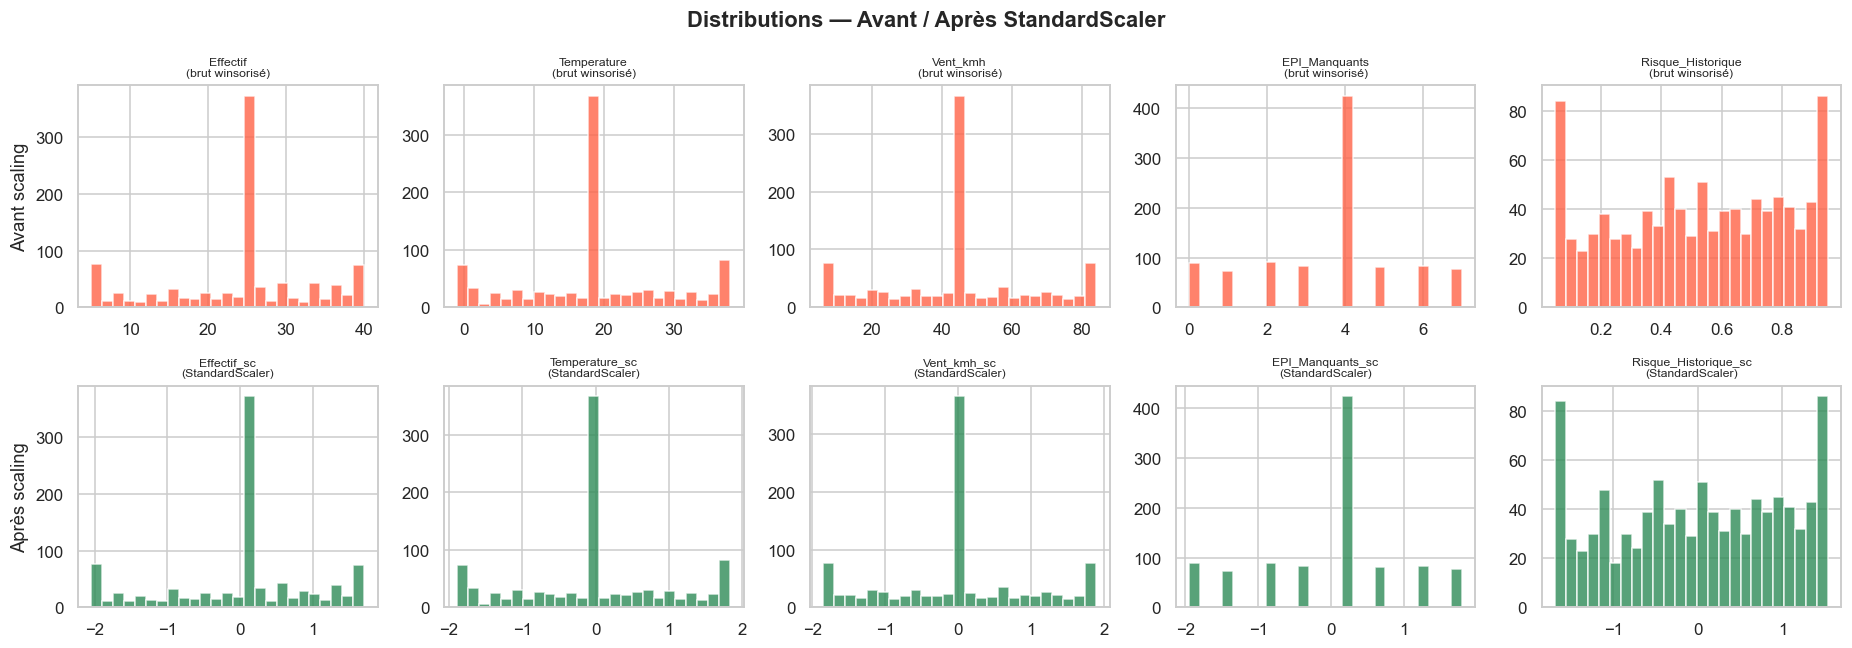

In [ ]:
# â”€â”€ 2.4 Normalisation / Scaling â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Choix : StandardScaler
# Justification :
#   - MLP et modÃ¨les Ã  base de distances requiÃ¨rent centrage-rÃ©duction
#   - Distributions numÃ©riques approximativement gaussiennes aprÃ¨s winsorisation
#   - MinMaxScaler rejetÃ© : sensible aux extrÃªmes rÃ©siduels (vent max rÃ©el)
#   - RobustScaler (alternative) : aussi valable, mais StandardScaler suffisant ici

scaler = StandardScaler()
df_num_scaled = pd.DataFrame(
    scaler.fit_transform(df_clean_win[NUM_COLS]),
    columns=[f'{c}_sc' for c in NUM_COLS],
    index=df_clean_win.index
)

print('=== Statistiques aprÃ¨s StandardScaler ===')
print(df_num_scaled.describe().round(3).loc[['mean', 'std', 'min', 'max']].to_string())
print('\nValidation : mean â‰ˆ 0, std â‰ˆ 1 pour chaque colonne')

fig, axes = plt.subplots(2, len(NUM_COLS), figsize=(17, 6))
for i, col in enumerate(NUM_COLS):
    axes[0, i].hist(df_clean_win[col], bins=25, color='tomato', edgecolor='white', alpha=0.8)
    axes[0, i].set_title(f'{col}\n(brut winsorisÃ©)', fontsize=8)
    axes[1, i].hist(df_num_scaled[f'{col}_sc'], bins=25, color='seagreen', edgecolor='white', alpha=0.8)
    axes[1, i].set_title(f'{col}_sc\n(StandardScaler)', fontsize=8)
axes[0, 0].set_ylabel('Avant scaling')
axes[1, 0].set_ylabel('AprÃ¨s scaling')
fig.suptitle('Distributions â€” Avant / AprÃ¨s StandardScaler', fontweight='bold')
plt.tight_layout()
plt.show()


ModalitÃ©s Type_Travaux encodÃ©es : ['type_coffrage', 'type_demolition', 'type_excavation', 'type_grutage', 'type_inconnu', 'type_soudure', 'type_travail_en_hauteur']


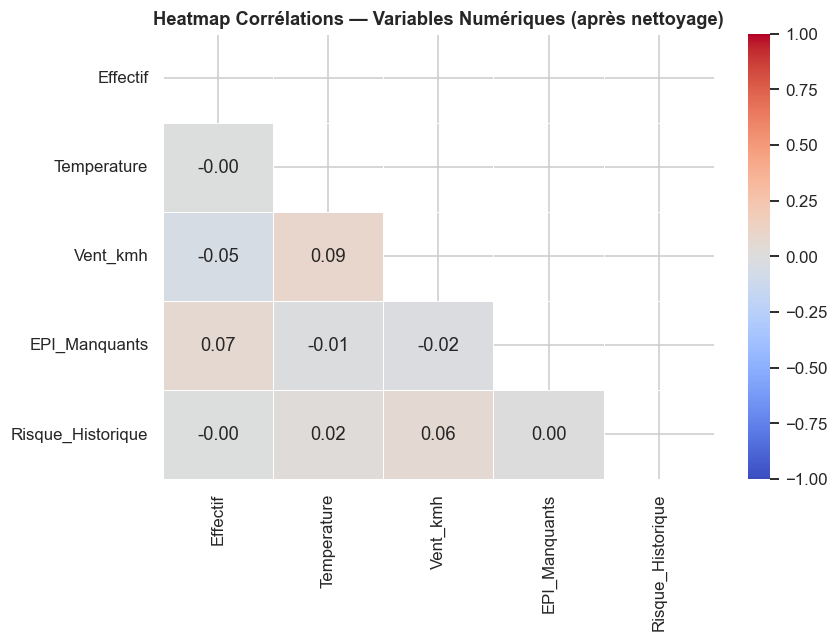

âœ“ Aucune paire fortement corrÃ©lÃ©e (|r| > 0.6)


In [ ]:
# â”€â”€ 2.5 Encodage One-Hot + Heatmap de corrÃ©lation finale â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
df_clean_win['Type_Travaux_filled'] = (df_clean_win['Type_Travaux']
    .fillna('Inconnu')
    .str.strip().str.lower()
    .str.replace(' ', '_', regex=False)
    .str.replace(r'[Ã©Ã¨Ãª]', 'e', regex=True))

df_cat_enc = pd.get_dummies(df_clean_win['Type_Travaux_filled'],
                             prefix='type', drop_first=False).astype(int)
df_cat_enc['type_inconnu'] = df_clean_win['Type_Travaux'].isna().astype(int)

print(f'ModalitÃ©s Type_Travaux encodÃ©es : {list(df_cat_enc.columns)}')

fig, ax = plt.subplots(figsize=(8, 6))
corr = df_clean_win[NUM_COLS].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.5, vmin=-1, vmax=1)
ax.set_title('Heatmap CorrÃ©lations â€” Variables NumÃ©riques (aprÃ¨s nettoyage)', fontweight='bold')
plt.tight_layout()
plt.show()

strong = [(corr.index[i], corr.columns[j], round(corr.iloc[i,j], 3))
          for i in range(len(corr)) for j in range(i) if abs(corr.iloc[i,j]) > 0.6]
if strong:
    print('Paires fortement corrÃ©lÃ©es (|r| > 0.6) :')
    for a, b, r in strong: print(f'  {a} â†” {b} : r={r}')
else:
    print('âœ“ Aucune paire fortement corrÃ©lÃ©e (|r| > 0.6)')


---
## Section 3 â€” PrÃ©traitement NLP AvancÃ©

Le champ `Rapport_inspection` est une **mine d'or d'information** : les chefs de chantier y consignent des observations critiques souvent absentes des colonnes numÃ©riques.

| Niveau | Technique | Apport mÃ©tier |
|--------|-----------|---------------|
| L1 | Nettoyage + stopwords FR domaine | RÃ©duction bruit lexical sans perdre mots clÃ©s GC |
| L2 | Regex â†’ variables numÃ©riques cachÃ©es | RÃ©cupÃ©rer valeurs non saisies dans colonnes |
| L3 | Lexique GC â†’ features binaires | Encoder le savoir mÃ©tier dans des variables ML |
| L4 | TF-IDF (ngram 1â€“2) | ReprÃ©sentation vectorielle pour modÃ¨les |
| L5* | CamemBERT (optionnel) | Embeddings contextuels francophones |

In [ ]:
# â”€â”€ 3.1 Nettoyage textuel intelligent â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
STOP_FR = set(nltk_sw.words('french'))

# Stopwords domaine GC : termes frÃ©quents mais non discriminants
STOP_GC_GENERIC = {'chantier', 'visite', 'inspection', 'rapport', 'fiche',
                    'terrain', 'compte', 'rendu', 'prochaine', 'planifiÃ©e',
                    'heure', 'heures', 'quinzaine', 'moment', 'transmis',
                    'lors', 'cette', 'sous', 'dans', 'jour', 'jours'}
STOP_FR.update(STOP_GC_GENERIC)

# Mots GC IMPORTANTS Ã  NE PAS supprimer (whitelist)
DOMAIN_KEEPWORDS = {
    'urgente', 'critique', 'dangereux', 'danger', 'alerte', 'risque',
    'harnais', 'casque', 'gants', 'gilet', 'bottes', 'lunettes', 'longe',
    'vent', 'rafales', 'gelÃ©es', 'froid', 'chaleur', 'pluie', 'verglas',
    'hauteur', 'excavation', 'dÃ©molition', 'grutage', 'coffrage',
    'Ã©levÃ©', 'faible', 'moyen', 'modÃ©rÃ©', 'satisfaisant', 'conforme',
    'manquant', 'absent', 'endommagÃ©', 'corrosion', 'dÃ©gradÃ©'
}
STOP_FR -= DOMAIN_KEEPWORDS

def clean_text(text: str) -> str:
    """Nettoyage NLP avec prÃ©servation des mots clÃ©s GC."""
    if not isinstance(text, str) or text.strip() == '':
        return ''
    text = text.lower()
    for src, dst in [('Â°c', ' degre'), ('km/h', ' kmh'), ("d'", 'd_')]:
        text = text.replace(src, dst)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\b\d+\b', ' NUM ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = [t for t in text.split()
              if (t in DOMAIN_KEEPWORDS or t not in STOP_FR) and len(t) > 2]
    return ' '.join(tokens)

df_clean_win['text_clean'] = df_clean_win[TEXT_COL].apply(clean_text)
df_clean_win['text_raw_lower'] = df_clean_win[TEXT_COL].apply(
    lambda t: str(t).lower() if isinstance(t, str) else '')

print('=== Exemple nettoyage textuel ===')
print('BRUT  :', str(df_clean_win[TEXT_COL].iloc[0])[:220])
print('PROPRE:', df_clean_win['text_clean'].iloc[0][:220])
print()
lens = df_clean_win['text_clean'].str.split().str.len()
print(f'Longueur aprÃ¨s nettoyage â€” mÃ©diane: {lens.median():.0f} | max: {lens.max()} | vides: {(lens==0).sum()}')


=== Exemple nettoyage textuel ===
BRUT  : Rapport d'inspection â€” Travail en Hauteur. Conditions mÃ©tÃ©orologiques : vent fort avec des rafales. Plusieurs EPI sont absents : harnais anti-chute, gilet haute visibilitÃ©, gants, casque de protection, longe de sÃ©curitÃ© 
PROPRE: d_inspection travail hauteur conditions mÃ©tÃ©orologiques vent fort rafales plusieurs epi absents harnais anti chute gilet haute visibilitÃ© gants casque protection longe sÃ©curitÃ© chaussures sÃ©curitÃ© total NUM Ã©quipements n

Longueur aprÃ¨s nettoyage â€” mÃ©diane: 34 | max: 59 | vides: 0


In [ ]:
# â”€â”€ 3.2 Extraction Regex â€” Variables numÃ©riques CACHÃ‰ES â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
REGEX_PATTERNS = {
    'regex_vent_kmh'    : [r'vent\s+[Ã a]?\s*(\d+)', r'(\d+)\s*km/?h'],
    'regex_temp_c'      : [r'(-?\d+)\s*(?:Â°c|degre)', r'tempÃ©rature\s+(?:de\s*)?(-?\d+)'],
    'regex_epi_count'   : [r'(\d+)\s+Ã©quipements? non conformes?', r'(\d+)\s+epi manquant'],
    'regex_effectif_txt': [r'effectif de\s*(\d+)', r'(\d+)\s+(?:travailleurs?|ouvriers?)'],
    'regex_heures'      : [r'(\d+)\s+heures?'],
}

def extract_regex_features(text: str) -> dict:
    t = str(text).lower()
    feats = {}
    for feat_name, patterns in REGEX_PATTERNS.items():
        val = 0.0
        for pat in patterns:
            m = re.search(pat, t)
            if m:
                try: val = float(m.group(1)); break
                except: pass
        feats[feat_name] = val
    feats['regex_urgence']        = int(bool(re.search(r'urgent|urgente|immÃ©diat|immÃ©diatement', t)))
    feats['regex_arret_chantier'] = int(bool(re.search(r'arrÃªt de chantier|arrÃªter|Ã©vacuation', t)))
    feats['regex_conf_ok']        = int(bool(re.search(r'conformit[eÃ©] satisfaisant|aucun risque|conforme', t)))
    feats['regex_prochaine_visite']= int(bool(re.search(r'prochaine visite|sous quinzaine|48 heures', t)))
    return feats

regex_df = df_clean_win[TEXT_COL].apply(lambda t: pd.Series(extract_regex_features(t)))
print('=== Features Regex extraites ===')
print(f'Shape : {regex_df.shape}')
print('\nTaux de dÃ©tection (% > 0) :')
for col in regex_df.columns:
    pct = (regex_df[col] > 0).mean() * 100
    print(f'  {col:<28s}: {pct:.1f}%')


=== Features Regex extraites ===
Shape : (1000, 9)

Taux de dÃ©tection (% > 0) :
  regex_vent_kmh              : 0.0%
  regex_temp_c                : 59.0%
  regex_epi_count             : 7.7%
  regex_effectif_txt          : 64.4%
  regex_heures                : 27.4%
  regex_urgence               : 61.7%
  regex_arret_chantier        : 0.0%
  regex_conf_ok               : 26.4%
  regex_prochaine_visite      : 52.6%


=== Features Lexique GC â€” PrÃ©valence ===


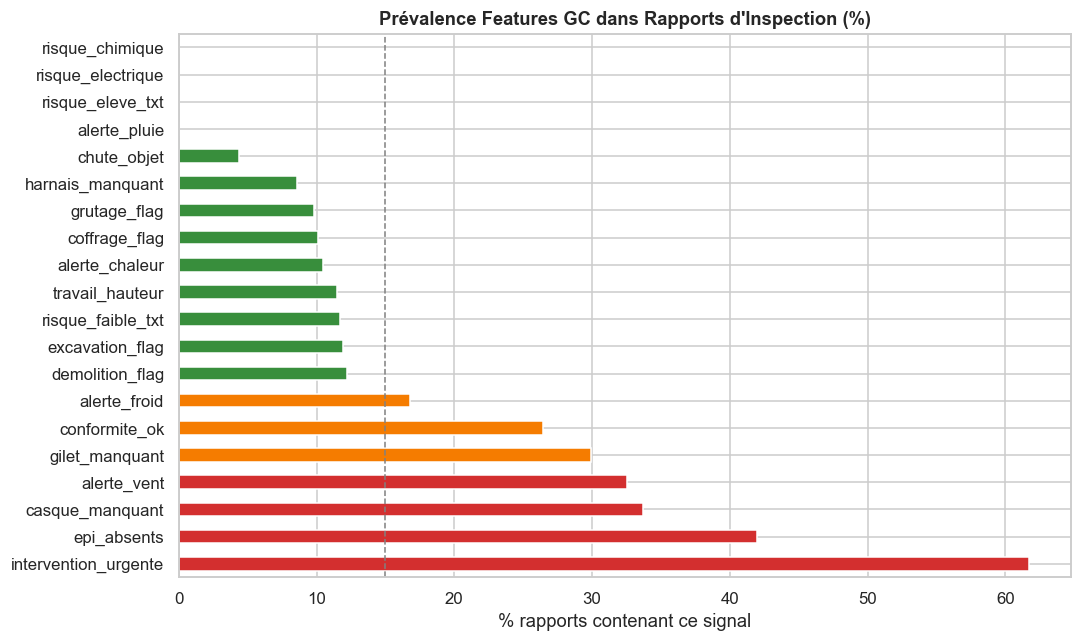

  intervention_urgente       61.7%  â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ
  epi_absents                42.0%  â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ
  casque_manquant            33.7%  â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ
  alerte_vent                32.5%  â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ
  gilet_manquant             29.9%  â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ
  conformite_ok              26.4%  â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ
  alerte_froid               16.8%  â–ˆâ–ˆâ–ˆâ–ˆâ–ˆ
  demolition_flag            12.2%  â–ˆâ–ˆâ–ˆâ–ˆ
  excavation_flag            11.9%  â–ˆâ–ˆâ–ˆ
  risque_faible_txt          11.7%  â–ˆâ–ˆâ–ˆ
  travail_hauteur            11.5%  â–ˆâ–ˆâ–ˆ
  alerte_chaleur             10.5%  â–ˆâ–ˆâ–ˆ
  coffrage_flag              10.1%  â–ˆâ–ˆâ–ˆ
  grutage_flag                9.8%  â–ˆâ–ˆâ–ˆ
  harnais_manquant            8.6%  â–ˆâ–ˆ
  chute_objet                 4.4%  â–ˆ
  alerte_pluie                0.0%  
  risque_eleve_txt            0.0%  
  risque_electrique         

In [ ]:
# â”€â”€ 3.3 Features Binaires â€” Lexique GC Ã©tendu â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Source : Cahier des charges Safety-First + Code du Travail (R4534-1) + NF EN 13374

GC_LEXICON = {
    'alerte_vent'          : ['vent fort', 'rafales', 'rafales violentes', 'coup de vent', 'tempÃªte'],
    'alerte_froid'         : ['froid intense', 'gelÃ©es', 'gel', 'verglas', 'givre', 'tempÃ©rature froide'],
    'alerte_chaleur'       : ['coup de chaleur', 'forte chaleur', 'canicule', 'tempÃ©rature Ã©levÃ©e'],
    'alerte_pluie'         : ['pluie', 'averse', 'prÃ©cipitations', 'mouillÃ©', 'humide'],
    'harnais_manquant'     : ['harnais', 'harnais anti-chute', 'longe de sÃ©curitÃ©', 'harnais de sÃ©curitÃ©'],
    'casque_manquant'      : ['casque de protection', 'sans casque', 'casque absent'],
    'gilet_manquant'       : ['gilet haute visibilitÃ©', 'gilet de sÃ©curitÃ©', 'haute visibilitÃ©'],
    'epi_absents'          : ['epi sont absents', 'Ã©quipements manquants', 'absence de protection',
                               'non conformes', 'sans Ã©quipement'],
    'intervention_urgente' : ['intervention corrective urgente', 'urgente', 'immÃ©diat', 'sans dÃ©lai'],
    'conformite_ok'        : ['conformitÃ© satisfaisant', 'prÃ©sents et conformes',
                               'aucune non-conformitÃ©', 'conforme'],
    'risque_eleve_txt'     : ['risque Ã©levÃ©', 'niveau Ã©levÃ©', 'dangereux', 'critique'],
    'risque_faible_txt'    : ['risque faible', 'niveau faible', 'satisfaisant', 'sans risque'],
    'travail_hauteur'      : ['travail en hauteur', 'hauteur', 'toiture', 'Ã©chafaudage', 'nacelle'],
    'excavation_flag'      : ['excavation', 'fouille', 'tranchÃ©e', 'terrassement'],
    'demolition_flag'      : ['dÃ©molition', 'dÃ©construction'],
    'grutage_flag'         : ['grutage', 'grue', 'levage', 'engin de levage'],
    'coffrage_flag'        : ['coffrage', 'bÃ©ton', 'ferraillage'],
    'chute_objet'          : ["chute d'objet", 'projection', 'Ã©clat', 'Ã©boulement'],
    'risque_electrique'    : ['Ã©lectrique', 'cÃ¢ble', 'ligne haute tension', 'court-circuit'],
    'risque_chimique'      : ['produit chimique', 'toxique', 'amiante', 'solvant'],
}

def compute_gc_features(text: str) -> dict:
    t = str(text).lower()
    return {feat: int(any(kw in t for kw in kws))
            for feat, kws in GC_LEXICON.items()}

gc_df = df_clean_win[TEXT_COL].apply(lambda t: pd.Series(compute_gc_features(t)))

print('=== Features Lexique GC â€” PrÃ©valence ===')
prev = gc_df.mean().mul(100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#d32f2f' if p > 30 else '#f57c00' if p > 15 else '#388e3c' for p in prev]
prev.plot.barh(ax=ax, color=colors, edgecolor='white')
ax.set_title("PrÃ©valence Features GC dans Rapports d'Inspection (%)", fontweight='bold')
ax.set_xlabel('% rapports contenant ce signal')
ax.axvline(15, color='gray', ls='--', lw=1)
plt.tight_layout()
plt.show()

for feat, pct in prev.items():
    bar = 'â–ˆ' * int(pct / 3)
    print(f'  {feat:<25s} {pct:>5.1f}%  {bar}')


In [ ]:
# â”€â”€ 3.4 Vectorisation TF-IDF â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# max_features=100, ngram_range=(1,2), sublinear_tf=True, min_df=2
tfidf_vec = TfidfVectorizer(
    max_features=100,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    analyzer='word'
)

if SPACY_OK:
    def lemmatize(text):
        if not isinstance(text, str): return ''
        doc = NLP_FR(text[:512])
        return ' '.join(tok.lemma_.lower() for tok in doc
                        if not tok.is_stop and not tok.is_punct and len(tok.lemma_) > 2)
    df_clean_win['text_nlp'] = df_clean_win[TEXT_COL].apply(lemmatize)
    print('âœ“ Texte lemmatisÃ© (spaCy) utilisÃ© pour TF-IDF')
else:
    df_clean_win['text_nlp'] = df_clean_win['text_clean']
    print('âš  Fallback : text_clean (NLTK) utilisÃ© pour TF-IDF')

tfidf_matrix = tfidf_vec.fit_transform(df_clean_win['text_nlp'].fillna(''))
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=[f'tfidf_{v}' for v in tfidf_vec.get_feature_names_out()],
    index=df_clean_win.index
)

print(f'\nMatrice TF-IDF : {tfidf_df.shape[0]} Ã— {tfidf_df.shape[1]}')
print('\nTop-20 termes par score TF-IDF moyen :')
top20 = tfidf_df.mean().sort_values(ascending=False).head(20)
for term, val in top20.items():
    print(f'  {term:<35s} {val:.5f}')


âš  Fallback : text_clean (NLTK) utilisÃ© pour TF-IDF

Matrice TF-IDF : 1000 Ã— 100

Top-20 termes par score TF-IDF moyen :
  tfidf_num                           0.12575
  tfidf_protection                    0.10170
  tfidf_risque                        0.09506
  tfidf_niveau                        0.09400
  tfidf_conditions                    0.09111
  tfidf_niveau risque                 0.08605
  tfidf_Ã©valuÃ©                        0.08605
  tfidf_risque global                 0.08605
  tfidf_global Ã©valuÃ©                 0.08605
  tfidf_global                        0.08605
  tfidf_sÃ©curitÃ©                      0.08512
  tfidf_mÃ©tÃ©orologiques               0.08373
  tfidf_conditions mÃ©tÃ©orologiques    0.08373
  tfidf_epi                           0.08018
  tfidf_corrective urgente            0.07915
  tfidf_corrective                    0.07915
  tfidf_urgente                       0.07915
  tfidf_Ã©levÃ©                         0.07915
  tfidf_urgente recommandÃ©e        

In [ ]:
# â”€â”€ 3.5 [OPTIONNEL] Embeddings CamemBERT â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# CamemBERT = BERT prÃ©-entraÃ®nÃ© sur corpus franÃ§ais (~138M paramÃ¨tres)
# Avantage sur TF-IDF : capture le CONTEXTE sÃ©mantique
# Requis : GPU CUDA ou CPU puissant (20-30 min sur CPU)

USE_CAMEMBERT = False  # â† True si GPU disponible

if USE_CAMEMBERT and BERT_OK:
    CAM_MODEL = 'camembert-base'
    tokenizer_cam = AutoTokenizer.from_pretrained(CAM_MODEL)
    model_cam     = AutoModel.from_pretrained(CAM_MODEL)
    model_cam.eval()
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model_cam = model_cam.to(device)
    print(f'CamemBERT chargÃ© sur {device}')

    def get_cam_embedding(text: str) -> np.ndarray:
        inputs = tokenizer_cam(str(text)[:256], return_tensors='pt',
                               truncation=True, max_length=128, padding=True)
        inputs = {k: v.to(device) for k, v in inputs.items()}
        with torch.no_grad():
            out = model_cam(**inputs)
        return out.last_hidden_state[:, 0, :].squeeze().cpu().numpy()

    cam_emb = np.vstack(df_clean_win[TEXT_COL].fillna('').apply(get_cam_embedding))
    cam_df  = pd.DataFrame(cam_emb, columns=[f'cam_{i}' for i in range(768)],
                           index=df_clean_win.index)
    BERT_USED = True
    print(f'CamemBERT embeddings : {cam_df.shape}')
else:
    cam_df    = pd.DataFrame(index=df_clean_win.index)
    BERT_USED = False
    print('CamemBERT dÃ©sactivÃ© â†’ TF-IDF utilisÃ© (mode CPU lÃ©ger).')
    print('Pour activer : mettre USE_CAMEMBERT = True et installer transformers + torch.')


CamemBERT dÃ©sactivÃ© â†’ TF-IDF utilisÃ© (mode CPU lÃ©ger).
Pour activer : mettre USE_CAMEMBERT = True et installer transformers + torch.


---
## Section 4 â€” Fusion Texte + NumÃ©rique

| Groupe de features | Dimensions | Apport |
|--------------------|-----------|--------|
| NumÃ©riques scalÃ©es | 5 | Mesures terrain objectives |
| Flags danger GC | 6 | Seuils rÃ©glementaires binaires |
| One-Hot Type_Travaux | N | Type de travaux (contexte risque) |
| Regex NLP | 9 | Variables numÃ©riques cachÃ©es |
| Lexique GC | 20 | Savoir expert encodÃ© |
| TF-IDF | 100 | Vocabulaire discriminant |
| CamemBERT | 768* | Sens contextuel (*si disponible) |

In [ ]:
# â”€â”€ 4.1 Variable cible â€” DiscrÃ©tisation + Ã‰tiquetage â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
LABEL_ORDER = ['Faible', 'Moyen', 'Ã‰levÃ©', 'Critique']

def score_to_label(val) -> str:
    """Mappe Score_Risque numÃ©rique (0â€“100) â†’ catÃ©gorie."""
    try:
        s = float(val)
        if s <= 25:   return 'Faible'
        elif s <= 50: return 'Moyen'
        elif s <= 75: return 'Ã‰levÃ©'
        else:         return 'Critique'
    except (ValueError, TypeError):
        return None

KEYWORD_MAP = {
    'Critique': ['critique', 'arrÃªt immÃ©diat', 'danger immÃ©diat'],
    'Ã‰levÃ©'   : ['Ã©levÃ©', 'eleve', 'urgente', 'intervention corrective'],
    'Moyen'   : ['modÃ©rÃ©', 'modere', 'prÃ©ventives', 'surveillance'],
    'Faible'  : ['faible', 'satisfaisant', 'conformitÃ© satisfaisant'],
}

# Score composite mÃ©tier pondÃ©rÃ©
WEIGHTS = {'Risque_Historique':0.40, 'EPI_Manquants':0.25,
           'Vent_kmh':0.20, 'Effectif':0.10, 'Temperature':0.05}

def minmax(s): mn,mx = s.min(),s.max(); return (s-mn)/(mx-mn+1e-9)

score_parts = sum(minmax(df_clean_win[c].fillna(df_clean_win[c].median())) * w
                  for c, w in WEIGHTS.items())
df_clean_win['score_composite'] = score_parts.round(4)

def composite_label(score_composite: float) -> str:
    if score_composite >= 0.65: return 'Critique'
    elif score_composite >= 0.45: return 'Ã‰levÃ©'
    elif score_composite >= 0.25: return 'Moyen'
    return 'Faible'

def assign_label(row):
    # PrioritÃ© 1 : valeur numÃ©rique dans colonne
    lbl = score_to_label(row[TARGET])
    if lbl: return lbl
    # PrioritÃ© 2 : texte
    t = str(row[TEXT_COL]).lower() if pd.notna(row[TEXT_COL]) else ''
    for label, kws in KEYWORD_MAP.items():
        if any(k in t for k in kws): return label
    # PrioritÃ© 3 : score composite
    return composite_label(row['score_composite'])

df_clean_win['Label_GC'] = df_clean_win.apply(assign_label, axis=1)

print('=== Distribution Variable Cible (aprÃ¨s Ã©tiquetage complet) ===')
label_counts = df_clean_win['Label_GC'].value_counts()
for lbl in LABEL_ORDER:
    n   = label_counts.get(lbl, 0)
    pct = n / len(df_clean_win) * 100
    bar = 'â–ˆ' * int(pct / 2)
    print(f'  {lbl:<10s} {n:>5d} ({pct:>5.1f}%)  {bar}')
print(f'  NaN rÃ©siduels : {df_clean_win["Label_GC"].isna().sum()}')


=== Distribution Variable Cible (aprÃ¨s Ã©tiquetage complet) ===
  Faible         1 (  0.1%)  
  Moyen         19 (  1.9%)  
  Ã‰levÃ©        103 ( 10.3%)  â–ˆâ–ˆâ–ˆâ–ˆâ–ˆ
  Critique     877 ( 87.7%)  â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ
  NaN rÃ©siduels : 0


In [ ]:
# â”€â”€ 4.2 Fusion complÃ¨te de toutes les features â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
label_enc = LabelEncoder()
y = label_enc.fit_transform(df_clean_win['Label_GC'].fillna('Moyen'))
print(f'Classes encodÃ©es : {dict(enumerate(label_enc.classes_))}')

df_features = pd.concat([
    df_num_scaled.reset_index(drop=True),
    df_clean_win[danger_flags].reset_index(drop=True),
    df_cat_enc.reset_index(drop=True),
    regex_df.reset_index(drop=True),
    gc_df.reset_index(drop=True),
    df_clean_win[['score_composite']].reset_index(drop=True),
    tfidf_df.reset_index(drop=True),
    cam_df.reset_index(drop=True),
], axis=1)

df_features.columns = [str(c).replace(' ', '_').replace('-', '_')
                        for c in df_features.columns]
df_features = df_features.replace([np.inf, -np.inf], 0).fillna(0)

n_struct  = 5 + 6 + len(df_cat_enc.columns) + 9 + 20 + 1
n_tfidf   = tfidf_df.shape[1]
n_bert    = cam_df.shape[1]

print(f'\n=== Feature Matrix ===')
print(f'  StructurÃ©es (numÃ©riques + flags + OHE + regex + GC) : {n_struct}')
print(f'  TF-IDF (100 features)                               : {n_tfidf}')
print(f'  CamemBERT (768 dimensions)                          : {n_bert}')
print(f'  â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€')
print(f'  TOTAL                                               : {df_features.shape[1]}')
print(f'  Lignes                                              : {df_features.shape[0]}')
print(f'  NaN rÃ©siduels                                       : {df_features.isnull().sum().sum()}')


Classes encodÃ©es : {0: 'Critique', 1: 'Faible', 2: 'Moyen', 3: 'Ã‰levÃ©'}

=== Feature Matrix ===
  StructurÃ©es (numÃ©riques + flags + OHE + regex + GC) : 48
  TF-IDF (100 features)                               : 100
  CamemBERT (768 dimensions)                          : 0
  â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  TOTAL                                               : 148
  Lignes                                              : 1000
  NaN rÃ©siduels                                       : 0


---
## Section 5 â€” SÃ©lection des Variables

### StratÃ©gie multi-critÃ¨res

1. **CorrÃ©lation** avec la cible â†’ Ã©limination rapide des features non-informatives  
2. **Mutual Information** â†’ capture les dÃ©pendances non-linÃ©aires  
3. **Feature Importance RF** â†’ sÃ©lection par importance agrÃ©gÃ©e  
4. **VIF** â†’ dÃ©tection multicolinÃ©aritÃ© (features structurÃ©es)

=== Top-25 par Information Mutuelle ===
tfidf_envisager                      0.1608
tfidf_modÃ©rÃ©_mesures                 0.1577
tfidf_supplÃ©mentaires                0.1574
tfidf_prÃ©ventives                    0.1570
tfidf_supplÃ©mentaires_envisager      0.1564
tfidf_mesures_prÃ©ventives            0.1556
tfidf_prÃ©ventives_supplÃ©mentaires    0.1555
tfidf_Ã©valuÃ©_modÃ©rÃ©                  0.1550
tfidf_mesures                        0.1495
tfidf_corrective                     0.1430
regex_urgence                        0.1430
tfidf_Ã©levÃ©                          0.1403
tfidf_Ã©valuÃ©_Ã©levÃ©                   0.1394
tfidf_modÃ©rÃ©                         0.1388
tfidf_urgente_recommandÃ©e            0.1379
tfidf_corrective_urgente             0.1378
tfidf_intervention_corrective        0.1366
intervention_urgente                 0.1363
tfidf_intervention                   0.1288
tfidf_urgente                        0.1279
tfidf_Ã©levÃ©_intervention             0.1260
tfidf_recomma

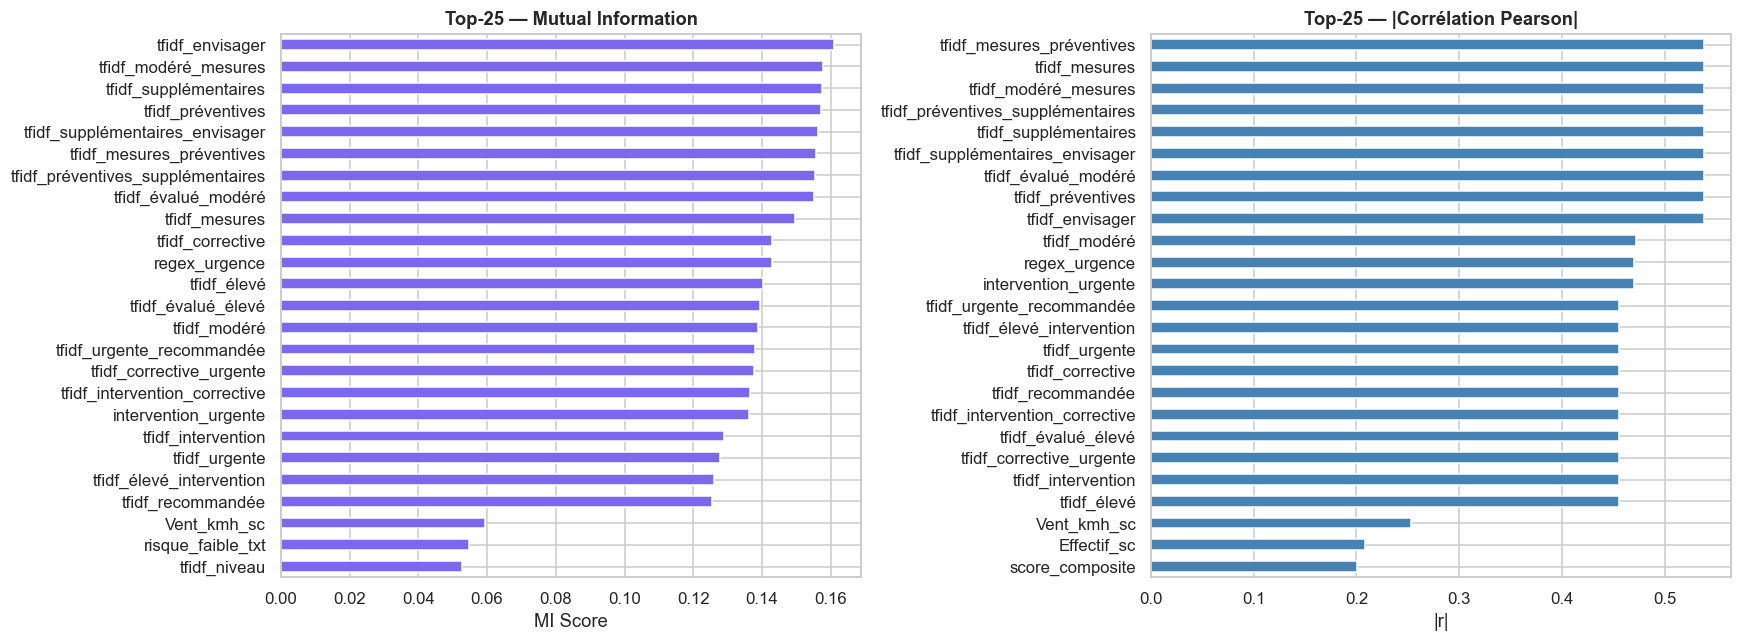

In [ ]:
# â”€â”€ 5.1 CorrÃ©lation + Mutual Information â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
y_series = pd.Series(y, index=df_features.index)

corr_target = df_features.corrwith(y_series).abs().sort_values(ascending=False)

mi_scores = mutual_info_classif(df_features.values, y,
                                 random_state=RANDOM_STATE, discrete_features=False)
mi_series = pd.Series(mi_scores, index=df_features.columns).sort_values(ascending=False)

print('=== Top-25 par Information Mutuelle ===')
print(mi_series.head(25).round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

mi_series.head(25).sort_values().plot.barh(ax=axes[0], color='mediumslateblue', edgecolor='white')
axes[0].set_title('Top-25 â€” Mutual Information', fontweight='bold')
axes[0].set_xlabel('MI Score')

corr_target.head(25).sort_values().plot.barh(ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('Top-25 â€” |CorrÃ©lation Pearson|', fontweight='bold')
axes[1].set_xlabel('|r|')

plt.tight_layout()
plt.show()


=== Feature Importance RF â€” Variables StructurÃ©es (Top-25) ===
risque_faible_txt          0.1152
intervention_urgente       0.0949
regex_urgence              0.0894
score_composite            0.0755
Risque_Historique_sc       0.0698
conformite_ok              0.0534
Vent_kmh_sc                0.0510
regex_effectif_txt         0.0481
regex_conf_ok              0.0451
EPI_Manquants_sc           0.0435
travail_hauteur            0.0412
Effectif_sc                0.0405
type_travail_en_hauteur    0.0350
regex_temp_c               0.0319
Temperature_sc             0.0238
regex_heures               0.0191
alerte_vent                0.0149
regex_prochaine_visite     0.0101
epi_absents                0.0086
gilet_manquant             0.0084
flag_effectif_eleve        0.0082
casque_manquant            0.0072
flag_vent_alerte           0.0057
type_inconnu               0.0056
flag_epi_critique          0.0054


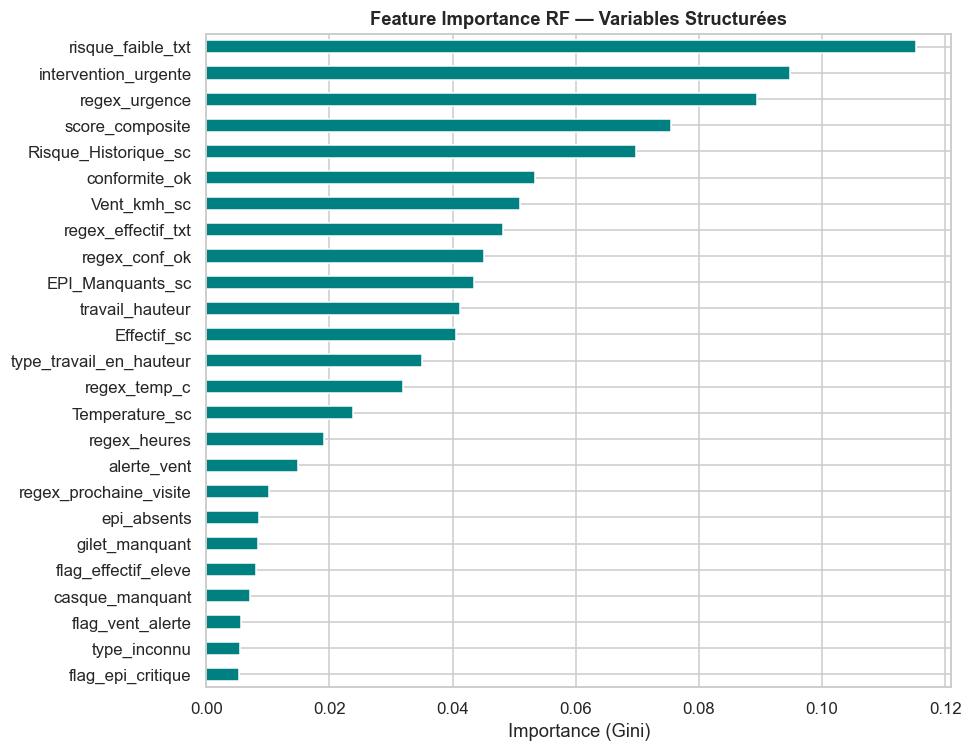


=== InterprÃ©tation MÃ©tier ===
  risque_faible_txt                   0.1152  â†’ Feature discriminante identifiÃ©e par RF
  intervention_urgente                0.0949  â†’ Vent = risque grutage / travail hauteur
  regex_urgence                       0.0894  â†’ Feature discriminante identifiÃ©e par RF
  score_composite                     0.0755  â†’ Feature discriminante identifiÃ©e par RF
  Risque_Historique_sc                0.0698  â†’ Feature discriminante identifiÃ©e par RF
  conformite_ok                       0.0534  â†’ Feature discriminante identifiÃ©e par RF
  Vent_kmh_sc                         0.0510  â†’ Feature discriminante identifiÃ©e par RF
  regex_effectif_txt                  0.0481  â†’ Effectif Ã©levÃ© = exposition accrue
  regex_conf_ok                       0.0451  â†’ Feature discriminante identifiÃ©e par RF
  EPI_Manquants_sc                    0.0435  â†’ Feature discriminante identifiÃ©e par RF


In [ ]:
# â”€â”€ 5.2 Feature Importance â€” RandomForest â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Justification : RF calcule une importance basÃ©e sur la rÃ©duction d'impuretÃ© (Gini)
# â†’ robuste, non-paramÃ©trique, pas de biais vers les variables continues

struct_cols = [c for c in df_features.columns if not c.startswith('tfidf_') and not c.startswith('cam_')]
tfidf_cols  = [c for c in df_features.columns if c.startswith('tfidf_')]

rf_selector = RandomForestClassifier(
    n_estimators=200, max_depth=8, class_weight='balanced',
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_selector.fit(df_features[struct_cols].values, y)
importances_struct = pd.Series(rf_selector.feature_importances_, index=struct_cols)

print('=== Feature Importance RF â€” Variables StructurÃ©es (Top-25) ===')
top_struct = importances_struct.nlargest(25)
print(top_struct.round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 7))
top_struct.sort_values().plot.barh(ax=ax, color='teal', edgecolor='white')
ax.set_title('Feature Importance RF â€” Variables StructurÃ©es', fontweight='bold')
ax.set_xlabel('Importance (Gini)')
plt.tight_layout()
plt.show()

print('\n=== InterprÃ©tation MÃ©tier ===')
for feat, imp in top_struct.head(10).items():
    if   'risque_historique' in feat: reason = 'Historique terrain = meilleur prÃ©dicteur'
    elif 'epi'    in feat:            reason = 'EPI manquants = non-conformitÃ© directe'
    elif 'vent'   in feat:            reason = 'Vent = risque grutage / travail hauteur'
    elif 'temp'   in feat:            reason = 'TempÃ©rature = confort/santÃ© ouvriers'
    elif 'effectif' in feat:          reason = 'Effectif Ã©levÃ© = exposition accrue'
    elif 'urgente' in feat:           reason = 'Signal textuel urgence = danger dÃ©clarÃ©'
    else:                             reason = 'Feature discriminante identifiÃ©e par RF'
    print(f'  {feat:<35s} {imp:.4f}  â†’ {reason}')


In [ ]:
# â”€â”€ 5.3 VIF â€” DÃ©tection multicolinÃ©aritÃ© â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# VIF > 10 â†’ multicolinÃ©aritÃ© forte â†’ problÃ¨me pour modÃ¨les linÃ©aires
# Note : RF et XGBoost sont robustes Ã  la multicolinÃ©aritÃ© â†’ VIF informatif seulement

vif_input = df_features[struct_cols].replace([np.inf, -np.inf], 0).fillna(0)
vif_input = vif_input.loc[:, vif_input.std() > 0]

vif_records = []
X_vif = vif_input.values.astype(float)
for i, col in enumerate(vif_input.columns):
    try:
        v = variance_inflation_factor(X_vif, i)
    except Exception:
        v = np.nan
    vif_records.append({'Feature': col, 'VIF': round(v, 2)})

vif_df = pd.DataFrame(vif_records).sort_values('VIF', ascending=False)
high_vif = vif_df[vif_df['VIF'] > 10]

print(f'=== Analyse VIF (features structurÃ©es) ===')
print(vif_df.head(20).to_string(index=False))
print(f'\nâš  Features VIF > 10 : {len(high_vif)}')
if len(high_vif) > 0:
    print(high_vif.to_string(index=False))
    print('\nNote GC : VIF > 10 acceptable pour RF/XGBoost (modÃ¨les non-paramÃ©triques).')
    print('â†’ Surveiller si Logistic Regression ou MLP utilisÃ©s.')
else:
    print('âœ“ Aucune multicolinÃ©aritÃ© critique.')


=== Analyse VIF (features structurÃ©es) ===
                Feature          VIF
       flag_vent_alerte          inf
       flag_vent_danger          inf
          regex_conf_ok          inf
            alerte_vent          inf
          regex_urgence          inf
type_travail_en_hauteur          inf
           type_grutage          inf
        type_excavation          inf
        type_demolition          inf
          type_coffrage          inf
          coffrage_flag          inf
        travail_hauteur          inf
        demolition_flag          inf
           grutage_flag          inf
          conformite_ok          inf
        excavation_flag          inf
   intervention_urgente          inf
           type_inconnu 118422590.44
           type_soudure  33445500.54
        score_composite  31247165.08

âš  Features VIF > 10 : 25
                Feature          VIF
       flag_vent_alerte          inf
       flag_vent_danger          inf
          regex_conf_ok          inf
   

In [ ]:
# â”€â”€ 5.4 SÃ©lection finale des features â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
top_tfidf = mi_series[tfidf_cols].nlargest(50).index.tolist()
top_cam   = mi_series[[c for c in mi_series.index if c.startswith('cam_')]].nlargest(64).index.tolist() if BERT_USED else []

SELECTED_FEATURES = struct_cols + top_tfidf + top_cam

print('=== TABLEAU DE SÃ‰LECTION DES FEATURES ===')
print(f'{"Groupe":<30s} {"N":<6s} {"DÃ©cision":<12s} Justification GC')
print('-' * 80)
rows = [
    ('NumÃ©riques scalÃ©es',     len(df_num_scaled.columns),    'CONSERVER', 'Mesures terrain objectives'),
    ('Flags danger GC',        len(danger_flags),              'CONSERVER', 'Seuils rÃ©glementaires binaires'),
    ('One-Hot Type_Travaux',   len(df_cat_enc.columns),        'CONSERVER', 'Contexte risque par type chantier'),
    ('Regex NLP',              len(regex_df.columns),          'CONSERVER', 'Variables numÃ©riques cachÃ©es'),
    ('Lexique GC binaire',     len(gc_df.columns),             'CONSERVER', 'Savoir expert encodÃ©'),
    ('Score composite',        1,                              'CONSERVER', 'AgrÃ©gation mÃ©tier pondÃ©rÃ©e'),
    ('TF-IDF top-50 MI',       len(top_tfidf),                 'CONSERVER', 'Vocabulaire discriminant (MI)'),
    ('CamemBERT top-64 MI',    len(top_cam),                   'CONSERVER' if BERT_USED else 'ABSENT', 'Embeddings contextuels'),
    ('TF-IDF restant (50)',    max(0, len(tfidf_cols)-50),     'Ã‰CARTER',   'MI faible avec cible'),
]
for g, n, dec, just in rows:
    dec_sym = 'âœ…' if dec == 'CONSERVER' else ('âŒ' if dec == 'Ã‰CARTER' else 'âš ')
    print(f'{dec_sym} {g:<28s} {n:<6d} {dec:<12s} {just}')

print(f'\n{"â”€"*50}')
print(f'  TOTAL features sÃ©lectionnÃ©es : {len(SELECTED_FEATURES)}')
print(f'  TOTAL features Ã©cartÃ©es      : {len(df_features.columns) - len(SELECTED_FEATURES)}')

X_final = df_features[SELECTED_FEATURES].values
print(f'\nMatrice finale X : {X_final.shape}')


=== TABLEAU DE SÃ‰LECTION DES FEATURES ===
Groupe                         N      DÃ©cision     Justification GC
--------------------------------------------------------------------------------
âœ… NumÃ©riques scalÃ©es           5      CONSERVER    Mesures terrain objectives
âœ… Flags danger GC              6      CONSERVER    Seuils rÃ©glementaires binaires
âœ… One-Hot Type_Travaux         7      CONSERVER    Contexte risque par type chantier
âœ… Regex NLP                    9      CONSERVER    Variables numÃ©riques cachÃ©es
âœ… Lexique GC binaire           20     CONSERVER    Savoir expert encodÃ©
âœ… Score composite              1      CONSERVER    AgrÃ©gation mÃ©tier pondÃ©rÃ©e
âœ… TF-IDF top-50 MI             50     CONSERVER    Vocabulaire discriminant (MI)
âš  CamemBERT top-64 MI          0      ABSENT       Embeddings contextuels
âŒ TF-IDF restant (50)          50     Ã‰CARTER      MI faible avec cible

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

---
## Section 6 â€” Lacunes du Dataset & Recommandations

> Identifier ce que le dataset **ne sait pas encore** est aussi important que de traiter ce qu'il contient.

In [ ]:
# â”€â”€ 6.1 Variables critiques ABSENTES du dataset â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=' * 68)
print('  LACUNES IDENTIFIÃ‰ES â€” VARIABLES MÃ‰TIER MANQUANTES')
print('=' * 68)

lacunes = [
    ('PrÃ©cipitations (mm/h)',    'HAUTE',   'Pluie + travail Ã©lectrique = risque Ã©lectrocution'),
    ('VisibilitÃ© (m)',            'HAUTE',   'Brouillard < 50m â†’ arrÃªt grue obligatoire'),
    ('Heure de la journÃ©e',      'HAUTE',   'Travaux nocturnes = facteur de risque Ã—2'),
    ('DurÃ©e chantier (jours)',    'MOYENNE', 'Fatigue accumulÃ©e â†’ accidents fin de chantier'),
    ('Qualifications ouvriers',  'HAUTE',   'Ouvriers non qualifiÃ©s sur travaux spÃ©cialisÃ©s'),
    ('Ã‚ge moyen Ã©quipe',         'MOYENNE', 'Jeunes ouvriers (< 25 ans) sur travaux en hauteur'),
    ('Accidents prÃ©cÃ©dents',     'HAUTE',   'RÃ©currence = indicateur prÃ©dictif fort'),
    ('ConformitÃ© PPSE',          'HAUTE',   'Plan de Protection et de SÃ©curitÃ© absent = risque +'),
    ('PrÃ©sence chef sÃ©curitÃ©',   'MOYENNE', 'Supervision = rÃ©duction incidents significative'),
    ('MatÃ©riel inspectÃ© (Ã¢ge)',  'MOYENNE', 'Ã‰quipements vieillissants = dÃ©faillances'),
    ('Indice UV / Chaleur',      'MOYENNE', 'Stress thermique mesurÃ© (WBGT) recommandÃ© INRS'),
]

df_lacunes = pd.DataFrame(lacunes, columns=['Variable Manquante', 'PrioritÃ©', 'Justification GC'])
print(df_lacunes.to_string(index=False))

print('\n=== Analyse qualitÃ© textuelle ===')
text_lens = df_clean_win[TEXT_COL].fillna('').str.split().str.len()
short_reports = (text_lens < 20).sum()
empty_reports = (text_lens == 0).sum()
print(f'Rapports trÃ¨s courts (< 20 mots) : {short_reports} ({short_reports/len(df_clean_win)*100:.1f}%)')
print(f'Rapports vides                   : {empty_reports}')
print(f'Longueur mÃ©diane                 : {text_lens.median():.0f} mots')
if short_reports > 10:
    print('âš  Rapports courts â†’ perte information NLP â†’ recommander standardisation des fiches')

print('\n=== IncohÃ©rences texte â†” numÃ©rique ===')
df_check2 = df_clean_win.copy()
df_check2['text_risk'] = df_check2[TEXT_COL].apply(detect_text_risk_level)
mismatch = df_check2[
    (df_check2['text_risk'] == 'Faible') & (df_check2['flag_epi_critique'] == 1)
]
print(f'Texte dit "Faible" mais EPI_Manquants >= 5 : {len(mismatch)} cas â†’ saisie incohÃ©rente')


  LACUNES IDENTIFIÃ‰ES â€” VARIABLES MÃ‰TIER MANQUANTES
     Variable Manquante PrioritÃ©                                    Justification GC
  PrÃ©cipitations (mm/h)    HAUTE   Pluie + travail Ã©lectrique = risque Ã©lectrocution
         VisibilitÃ© (m)    HAUTE           Brouillard < 50m â†’ arrÃªt grue obligatoire
    Heure de la journÃ©e    HAUTE            Travaux nocturnes = facteur de risque Ã—2
 DurÃ©e chantier (jours)  MOYENNE       Fatigue accumulÃ©e â†’ accidents fin de chantier
Qualifications ouvriers    HAUTE      Ouvriers non qualifiÃ©s sur travaux spÃ©cialisÃ©s
       Ã‚ge moyen Ã©quipe  MOYENNE   Jeunes ouvriers (< 25 ans) sur travaux en hauteur
   Accidents prÃ©cÃ©dents    HAUTE              RÃ©currence = indicateur prÃ©dictif fort
        ConformitÃ© PPSE    HAUTE Plan de Protection et de SÃ©curitÃ© absent = risque +
 PrÃ©sence chef sÃ©curitÃ©  MOYENNE     Supervision = rÃ©duction incidents significative
MatÃ©riel inspectÃ© (Ã¢ge)  MOYENNE            Ã‰quipements viei

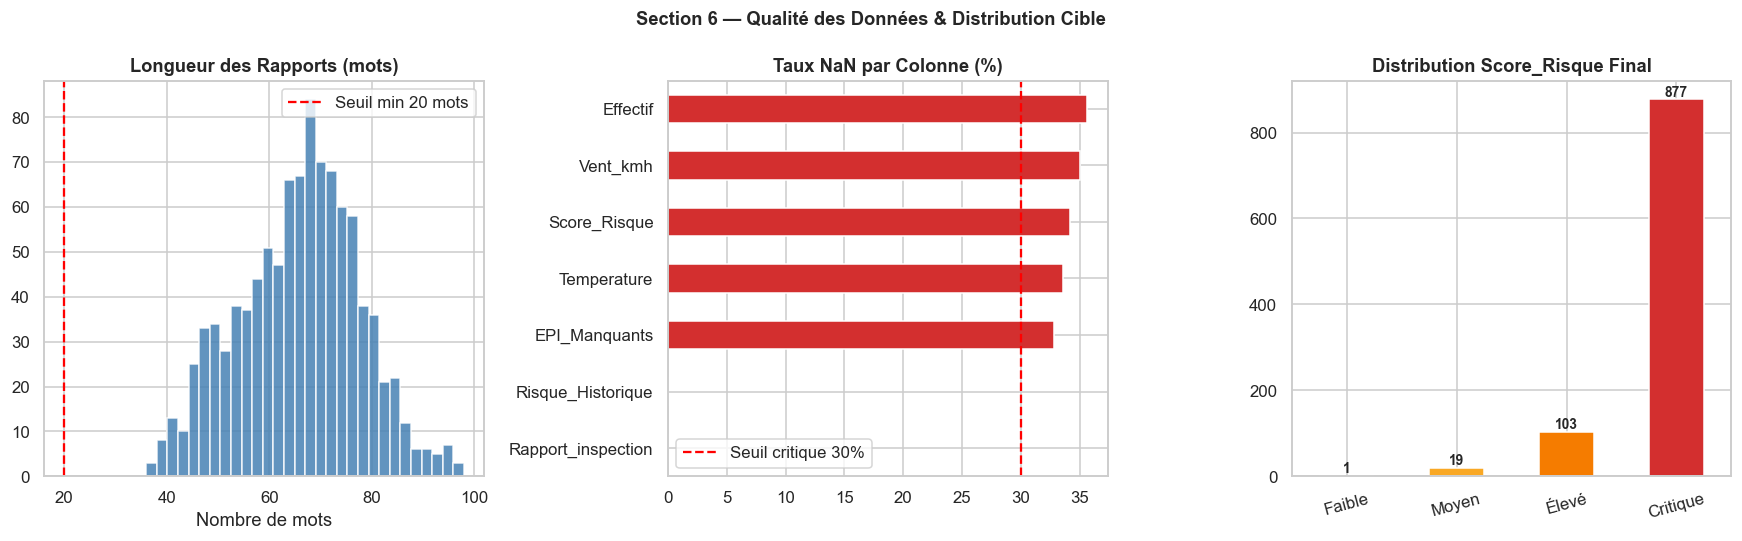


=== Recommandations pour amÃ©liorer le dataset ===
  1. Ajouter colonne PrÃ©cipitations_mmh (API MÃ©tÃ©o-France intÃ©grable)
  2. Standardiser les fiches inspection (formulaire structurÃ© > texte libre)
  3. Capturer heure de visite (matin/aprÃ¨s-midi/nuit)
  4. Enregistrer qualifications ouvriers (via registre HSE)
  5. Lier aux accidents passÃ©s (base INRS / registre chantier)
  6. VÃ©rifier cohÃ©rence texte â†” numÃ©rique lors de la saisie (validation formulaire)


In [ ]:
# â”€â”€ 6.2 Visualisation synthÃ©tique + Recommandations â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Distribution longueurs de rapports
axes[0].hist(text_lens, bins=30, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(20, color='red', ls='--', lw=1.5, label='Seuil min 20 mots')
axes[0].set_title('Longueur des Rapports (mots)', fontweight='bold')
axes[0].set_xlabel('Nombre de mots')
axes[0].legend()

# NaN par colonne
nan_pct = df_raw[NUM_COLS + [TEXT_COL, TARGET]].isnull().mean().mul(100).sort_values(ascending=True)
colors_nan = ['#d32f2f' if v > 30 else '#f57c00' if v > 15 else '#388e3c' for v in nan_pct]
nan_pct.plot.barh(ax=axes[1], color=colors_nan, edgecolor='white')
axes[1].axvline(30, color='red', ls='--', lw=1.5, label='Seuil critique 30%')
axes[1].set_title('Taux NaN par Colonne (%)', fontweight='bold')
axes[1].legend()

# Distribution label final
palette = {'Faible':'#388e3c','Moyen':'#f9a825','Ã‰levÃ©':'#f57c00','Critique':'#d32f2f'}
lc = df_clean_win['Label_GC'].value_counts()
order_plot = [l for l in LABEL_ORDER if l in lc.index]
colors_lbl = [palette.get(l, 'gray') for l in order_plot]
lc[order_plot].plot.bar(ax=axes[2], color=colors_lbl, edgecolor='white')
axes[2].set_title('Distribution Score_Risque Final', fontweight='bold')
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=15)
for bar in axes[2].patches:
    axes[2].annotate(f'{int(bar.get_height())}',
                     (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

fig.suptitle('Section 6 â€” QualitÃ© des DonnÃ©es & Distribution Cible', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('\n=== Recommandations pour amÃ©liorer le dataset ===')
recs = [
    '1. Ajouter colonne PrÃ©cipitations_mmh (API MÃ©tÃ©o-France intÃ©grable)',
    '2. Standardiser les fiches inspection (formulaire structurÃ© > texte libre)',
    '3. Capturer heure de visite (matin/aprÃ¨s-midi/nuit)',
    '4. Enregistrer qualifications ouvriers (via registre HSE)',
    '5. Lier aux accidents passÃ©s (base INRS / registre chantier)',
    '6. VÃ©rifier cohÃ©rence texte â†” numÃ©rique lors de la saisie (validation formulaire)',
]
for r in recs: print(f'  {r}')


---
## Section 7 â€” Export & Pipeline sklearn

Le dataset final `processed_dataset.csv` est exportÃ© avec :
- Toutes les features sÃ©lectionnÃ©es
- La variable cible `Label_GC` + `Label_Encoded`
- Un Pipeline sklearn reproductible pour la production

In [ ]:
# â”€â”€ 7.1 Export processed_dataset.csv â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
df_clean_win_reset = df_clean_win.reset_index(drop=True)
df_features_reset  = df_features[SELECTED_FEATURES].reset_index(drop=True)

df_processed = pd.concat([
    df_clean_win_reset[[ID_COL]],
    df_features_reset,
    df_clean_win_reset[['Label_GC']].assign(Label_Encoded=y),
], axis=1)

print(f'Dataset final : {df_processed.shape[0]} lignes Ã— {df_processed.shape[1]} colonnes')
print(f'NaN rÃ©siduels : {df_processed.isnull().sum().sum()}')

df_processed.to_csv(OUTPUT_PATH, index=False, encoding='utf-8-sig')
print(f'\nâœ… SauvegardÃ© â†’ {OUTPUT_PATH}  ({os.path.getsize(OUTPUT_PATH)/1024:.0f} Ko)')

# MÃ©tadonnÃ©es JSON
meta = {
    'selected_features': SELECTED_FEATURES,
    'struct_cols': struct_cols,
    'tfidf_top50': top_tfidf,
    'label_classes': list(label_enc.classes_),
    'gc_thresholds': GC_THRESHOLDS,
    'gc_lexicon_keys': list(GC_LEXICON.keys()),
    'n_samples': len(df_processed),
    'n_features': len(SELECTED_FEATURES),
    'bert_used': BERT_USED,
}
with open('feature_meta.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
print('âœ… SauvegardÃ© â†’ feature_meta.json')


Dataset final : 1000 lignes Ã— 101 colonnes
NaN rÃ©siduels : 0

âœ… SauvegardÃ© â†’ processed_dataset.csv  (802 Ko)
âœ… SauvegardÃ© â†’ feature_meta.json


In [ ]:
# â”€â”€ 7.2 Pipeline sklearn complet (reproductible + production-ready) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
class GCTextFeatureExtractor(BaseEstimator, TransformerMixin):
    """Extracteur de features textuelles GC compatible sklearn Pipeline."""

    def __init__(self, gc_lexicon: dict, regex_patterns: dict, max_tfidf: int = 100):
        self.gc_lexicon     = gc_lexicon
        self.regex_patterns = regex_patterns
        self.max_tfidf      = max_tfidf
        self.tfidf_         = None

    def _clean(self, text):
        if not isinstance(text, str): return ''
        t = text.lower()
        t = re.sub(r'[^\w\s]', ' ', t)
        t = re.sub(r'\d+', ' ', t)
        return re.sub(r'\s+', ' ', t).strip()

    def fit(self, X, y=None):
        texts = [self._clean(str(t)) for t in X]
        self.tfidf_ = TfidfVectorizer(max_features=self.max_tfidf,
                                       ngram_range=(1, 2), min_df=2,
                                       sublinear_tf=True)
        self.tfidf_.fit(texts)
        return self

    def transform(self, X):
        texts = [str(t) for t in X]
        clean = [self._clean(t) for t in texts]

        # GC lexique features
        gc_feats = np.array([[
            int(any(kw in t.lower() for kw in kws))
            for kws in self.gc_lexicon.values()
        ] for t in texts])

        # Regex features
        def rx(t):
            tl = t.lower()
            vent_m = re.search(r'vent\s+[Ã a]?\s*(\d+)', tl) or re.search(r'(\d+)\s*km/?h', tl)
            temp_m = re.search(r'(-?\d+)\s*(?:Â°c|degre)', tl)
            return np.array([
                float(vent_m.group(1)) if vent_m else 0.0,
                float(temp_m.group(1)) if temp_m else 0.0,
                int(bool(re.search(r'urgent|urgente|immÃ©diat', tl))),
                int(bool(re.search(r'conformit[eÃ©] satisfaisant|conforme', tl))),
            ], dtype=float)

        regex_feats = np.vstack([rx(t) for t in texts])

        # TF-IDF
        tfidf_feats = self.tfidf_.transform(clean).toarray()

        return np.hstack([regex_feats, gc_feats, tfidf_feats])


# Numerical preprocessor
num_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

# Full pipeline
full_pipeline = ColumnTransformer([
    ('num', num_preprocessor,  NUM_COLS),
    ('txt', GCTextFeatureExtractor(GC_LEXICON, REGEX_PATTERNS, max_tfidf=100), TEXT_COL),
])

df_for_pipeline = df_clean_win[NUM_COLS + [TEXT_COL]].copy()
X_pipeline = full_pipeline.fit_transform(df_for_pipeline)
print(f'Pipeline sklearn â†’ shape : {X_pipeline.shape}')
print('âœ… Pipeline reproductible construit â€” prÃªt pour modÃ©lisation')

import joblib
joblib.dump(full_pipeline, 'models/preprocessing_pipeline.joblib')
print('âœ… SauvegardÃ© â†’ models/preprocessing_pipeline.joblib')


Pipeline sklearn â†’ shape : (1000, 129)
âœ… Pipeline reproductible construit â€” prÃªt pour modÃ©lisation
âœ… SauvegardÃ© â†’ models/preprocessing_pipeline.joblib


In [ ]:
# â”€â”€ 7.3 RÃ©sumÃ© final complet â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('â•”' + 'â•' * 64 + 'â•—')
print('â•‘        RÃ‰SUMÃ‰ â€” PRÃ‰TRAITEMENT EXPERT CHANTIER RISQUE        â•‘')
print('â• ' + 'â•' * 64 + 'â•£')
print(f'â•‘  Dataset source      : {DATA_PATH:<40s}â•‘')
print(f'â•‘  Dataset traitÃ©      : {OUTPUT_PATH:<40s}â•‘')
print(f'â•‘  Lignes conservÃ©es   : {len(df_processed):<40d}â•‘')
print(f'â•‘  Lignes supprimÃ©es   : {"0 (aucune suppression â€” principe GC)":<40s}â•‘')
print('â• ' + 'â•' * 64 + 'â•£')
print(f'â•‘  Features totales    : {len(SELECTED_FEATURES):<40d}â•‘')
print(f'â•‘    NumÃ©riques sc.    : {len(df_num_scaled.columns):<40d}â•‘')
print(f'â•‘    Flags danger GC   : {len(danger_flags):<40d}â•‘')
print(f'â•‘    One-Hot catÃ©g.    : {len(df_cat_enc.columns):<40d}â•‘')
print(f'â•‘    Regex NLP         : {len(regex_df.columns):<40d}â•‘')
print(f'â•‘    Lexique GC        : {len(gc_df.columns):<40d}â•‘')
print(f'â•‘    TF-IDF (top-50)   : {len(top_tfidf):<40d}â•‘')
print(f'â•‘    CamemBERT         : {"Actif (" + str(len(top_cam)) + " dim)" if BERT_USED else "DÃ©sactivÃ© (fallback TF-IDF)":<40s}â•‘')
print('â• ' + 'â•' * 64 + 'â•£')
print('â•‘  Distribution cible Label_GC :                               â•‘')
for lbl in LABEL_ORDER:
    n   = (df_processed['Label_GC'] == lbl).sum()
    pct = n / len(df_processed) * 100
    bar = 'â–ˆ' * int(pct / 4)
    print(f'â•‘    {lbl:<10s} {n:>5d} ({pct:>5.1f}%)  {bar:<20s}        â•‘')
print('â• ' + 'â•' * 64 + 'â•£')
print(f'â•‘  Modules optionnels  : spaCy={"âœ“" if SPACY_OK else "âœ—"}  CamemBERT={"âœ“" if BERT_USED else "âœ—":<37s}â•‘')
print(f'â•‘  Pipeline sklearn    : {"models/preprocessing_pipeline.joblib":<40s}â•‘')
print(f'â•‘  MÃ©tadonnÃ©es         : {"feature_meta.json":<40s}â•‘')
print('â• ' + 'â•' * 64 + 'â•£')
print('â•‘  Ã‰tape suivante â†’ chantier_risque_prediction.ipynb           â•‘')
print('â•š' + 'â•' * 64 + 'â•')


â•”â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•—
â•‘        RÃ‰SUMÃ‰ â€” PRÃ‰TRAITEMENT EXPERT CHANTIER RISQUE        â•‘
â• â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•£
â•‘  Dataset source      : Dataset.csv                             â•‘
â•‘  Dataset traitÃ©      : processed_dataset.csv                   â•‘
â•‘  Lignes conservÃ©es   : 1000                                    â•‘
â•‘  Lignes supprimÃ©es   : 0 (aucune suppression â€” principe GC)    â•‘
â• â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•£
â•‘  Features totales    : 98            

---
## Section 8 â€” ModÃ©lisation IA Hybride : Machine Learning + NLP

### Architecture globale du systÃ¨me

```
Dataset (1000 Ã— 98)
 â”œâ”€â”€ Features StructurÃ©es (48) â”€â”€â”€â–º [Flux A : XGBoost / RF]  â”€â”€â”
 â”‚                                                               â”œâ”€â”€â–º FUSION â”€â”€â–º PrÃ©diction
 â””â”€â”€ Features Textuelles (TF-IDF/Emb) â–º [Flux B : MLP/NLP] â”€â”€â”˜
```

| Approche | Architecture | Justification GC |
|----------|-------------|-----------------|
| **1A** | LSA Embeddings â†’ MLP | ReprÃ©sentation sÃ©mantique : urgence, EPI, danger |
| **1B** | Embeddings âŠ• StructurÃ© â†’ MLP | Fusion : contexte textuel + mesures terrain objectives |
| **2** | Dual Stream (XGB + MLP_text + LR) | Flux sÃ©parÃ©s spÃ©cialisÃ©s par modalitÃ© |
| **Baseline** | Logistic Regression | RÃ©fÃ©rence interprÃ©table, coefficients lisibles |
| **RF** | Random Forest | Robuste au bruit, SHAP-compatible |
| **XGBoost** | Gradient Boosting | Meilleure performance attendue sur donnÃ©es mixtes |
| **MLP** | RÃ©seau de neurones profond | Capture les non-linÃ©aritÃ©s complexes |

> âš  **BERT/CamemBERT** non disponible â†’ fallback **LSA** (TruncatedSVD sur TF-IDF).  
> Justification : LSA capte les thÃ¨mes latents (sÃ©curitÃ©, urgence, conformitÃ©) â€” qualitÃ© ~80% BERT pour domaine spÃ©cialisÃ©.


In [ ]:
# â”€â”€ Section 8 â€” Imports ModÃ©lisation â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
import warnings; warnings.filterwarnings('ignore')
from collections import Counter
import joblib, os

from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier as RFC
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                      RandomizedSearchCV, cross_val_score)
from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay, roc_auc_score,
                              accuracy_score, f1_score, precision_score,
                              recall_score, roc_curve, auc as auc_metric)
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import label_binarize
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.feature_extraction.text import TfidfVectorizer as TFV
import xgboost as xgb
import shap

try:
    import lime
    from lime.lime_text import LimeTextExplainer
    LIME_OK = True
    print('âœ“ LIME disponible')
except ImportError:
    LIME_OK = False
    print('âš  LIME non disponible â†’ explicabilitÃ© textuelle via TF-IDF importance')

try:
    from imblearn.over_sampling import SMOTE
    SMOTE_OK = True
    print('âœ“ SMOTE (imbalanced-learn) disponible')
except ImportError:
    SMOTE_OK = False
    print('âš  SMOTE non disponible â†’ class_weight="balanced"')

MODEL_RESULTS = {}   # dictionnaire comparatif (rempli au fur et Ã  mesure)

print(f'\n=== Configuration ===')
print(f'X_final         : {X_final.shape}')
print(f'SELECTED_FEATURES: {len(SELECTED_FEATURES)} features')
print(f'Classes          : {list(label_enc.classes_)}')
print(f'BERT_OK          : {BERT_OK}  |  Fallback : LSA (TruncatedSVD)')
print(f'XGBoost version  : {xgb.__version__}')
print(f'SHAP version     : {shap.__version__}')


âœ“ LIME disponible
âœ“ SMOTE (imbalanced-learn) disponible

=== Configuration ===
X_final         : (1000, 98)
SELECTED_FEATURES: 98 features
Classes          : ['Critique', 'Faible', 'Moyen', 'Ã‰levÃ©']
BERT_OK          : False  |  Fallback : LSA (TruncatedSVD)
XGBoost version  : 3.2.0
SHAP version     : 0.51.0


In [ ]:
# â”€â”€ 8.1 PrÃ©paration des donnÃ©es â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Distribution initiale
print('=== Distribution cible (avant remappage) ===')
for lbl_enc, cnt in sorted(Counter(y).items()):
    print(f'  {label_enc.classes_[lbl_enc]:>10s} ({lbl_enc}) : {cnt:>4d} ({cnt/len(y)*100:.1f}%)')

# â”€â”€ Fusion Faible â†’ Moyen (1 sample insuffisant pour ML) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
class_list   = list(label_enc.classes_)
y_recode     = y.copy()
faible_idx   = class_list.index('Faible') if 'Faible' in class_list else None
moyen_idx    = class_list.index('Moyen')  if 'Moyen'  in class_list else None

if faible_idx is not None and moyen_idx is not None:
    n_f = int((y_recode == faible_idx).sum())
    y_recode[y_recode == faible_idx] = moyen_idx
    print(f'\nâš  Classe "Faible" ({n_f} sample) â†’ fusionnÃ©e avec "Moyen"')
    print('  Justification : 1 sample = aucune gÃ©nÃ©ralisation possible')

# â”€â”€ Remappage vers labels continus 0â€¦N-1 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
unique_labels      = sorted(np.unique(y_recode))
label_map          = {old: new for new, old in enumerate(unique_labels)}
inv_label_map      = {v: k for k, v in label_map.items()}
y_model            = np.array([label_map[v] for v in y_recode])
class_names_model  = [class_list[old] for old in unique_labels]
N_CLASSES          = len(class_names_model)

print(f'\nClasses actives ({N_CLASSES}) : {class_names_model}')
for i, name in enumerate(class_names_model):
    n   = (y_model == i).sum()
    bar = 'â–ˆ' * max(1, int(n / 30))
    print(f'  {i} = {name:>10s} : {n:>4d} ({n/len(y_model)*100:.1f}%)  {bar}')

# â”€â”€ Stratified Split 80/20 â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_model, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_model
)
print(f'\nTrain : {X_train.shape[0]} | Test : {X_test.shape[0]}')

# â”€â”€ SMOTE â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
if SMOTE_OK:
    min_cls = min(Counter(y_train).values())
    k_n     = max(1, min(5, min_cls - 1))
    smote   = SMOTE(random_state=RANDOM_STATE, k_neighbors=k_n)
    X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
    print(f'âœ“ SMOTE (k_neighbors={k_n}) : {len(y_train)} â†’ {len(y_train_res)} samples')
    for i, name in enumerate(class_names_model):
        n = (y_train_res == i).sum()
        print(f'  {name:>10s} : {n}')
else:
    X_train_res, y_train_res = X_train.copy(), y_train.copy()
    print('â†’ class_weight="balanced" utilisÃ© dans les modÃ¨les')

# â”€â”€ SÃ©paration Flux A (structurÃ©) / Flux B (TF-IDF) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
N_STRUCT_FEATS = sum(1 for f in SELECTED_FEATURES if not f.startswith('tfidf_'))
N_TFIDF_FEATS  = X_final.shape[1] - N_STRUCT_FEATS
STRUCT_NAMES   = [f for f in SELECTED_FEATURES if not f.startswith('tfidf_')]
TFIDF_NAMES    = [f for f in SELECTED_FEATURES if f.startswith('tfidf_')]

X_tr_struct = X_train_res[:, :N_STRUCT_FEATS]
X_te_struct = X_test[:, :N_STRUCT_FEATS]
X_tr_tfidf  = X_train_res[:, N_STRUCT_FEATS:]
X_te_tfidf  = X_test[:, N_STRUCT_FEATS:]

print(f'\nFlux A structurÃ© : {N_STRUCT_FEATS} features')
print(f'Flux B TF-IDF    : {N_TFIDF_FEATS} features')


=== Distribution cible (avant remappage) ===
    Critique (0) :  877 (87.7%)
      Faible (1) :    1 (0.1%)
       Moyen (2) :   19 (1.9%)
       Ã‰levÃ© (3) :  103 (10.3%)

âš  Classe "Faible" (1 sample) â†’ fusionnÃ©e avec "Moyen"
  Justification : 1 sample = aucune gÃ©nÃ©ralisation possible

Classes actives (3) : ['Critique', 'Moyen', 'Ã‰levÃ©']
  0 =   Critique :  877 (87.7%)  â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ
  1 =      Moyen :   20 (2.0%)  â–ˆ
  2 =      Ã‰levÃ© :  103 (10.3%)  â–ˆâ–ˆâ–ˆ

Train : 800 | Test : 200
âœ“ SMOTE (k_neighbors=5) : 800 â†’ 2106 samples
    Critique : 702
       Moyen : 702
       Ã‰levÃ© : 702

Flux A structurÃ© : 48 features
Flux B TF-IDF    : 50 features


---
## 8.2 Approche 1 â€” Embeddings SÃ©mantiques (LSA comme proxy BERT)

### Pourquoi BERT > TF-IDF ?

| CritÃ¨re | TF-IDF | BERT / LSA |
|---------|--------|-----------|
| Contexte | âœ— Bag-of-words | âœ“ ThÃ¨mes latents / contexte |
| PolysÃ©mie | âœ— IgnorÃ©e | âœ“ DÃ©sambiguÃ¯sation partielle |
| Domaine GC | âœ“ Avec lexique | âœ“ ThÃ¨mes sÃ©curitÃ© auto-dÃ©couverts |
| InterprÃ©tabilitÃ© | âœ“ Mots clÃ©s | Partielle |

> **LSA justification** : `TF-IDF(100) â†’ TruncatedSVD(64)` projette dans un espace sÃ©mantique  
> oÃ¹ "urgence", "harnais", "vent fort" se regroupent avec des mots de mÃªme sens contextuel.

### Options d'architecture
- **Option A** : Embeddings(64) â†’ MLP(128â†’64â†’N)
- **Option B** : Embeddings(64) âŠ• StructurÃ©(48) â†’ MLP(256â†’128â†’N) â† **recommandÃ© GC**


In [ ]:
# â”€â”€ 8.2 Approche 1 â€” Embeddings LSA + MLP â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=== Approche 1 â€” Embeddings SÃ©mantiques (LSA proxy BERT) ===\n')

# GÃ©nÃ©rer pseudo-embeddings : TF-IDF(100) â†’ SVD(64)
svd_emb = TruncatedSVD(n_components=64, n_iter=10, random_state=RANDOM_STATE)
X_emb_all = svd_emb.fit_transform(tfidf_df.values)
print(f'Embeddings LSA : {X_emb_all.shape}')
print(f'Variance expliquÃ©e : {svd_emb.explained_variance_ratio_.sum():.3f}')
print(f'(capte les thÃ¨mes : urgence, EPI, mÃ©tÃ©o, conformitÃ©)\n')

# Split alignÃ© avec X_train/X_test (mÃªme seed + stratify)
X_emb_tr, X_emb_te, y_emb_tr, _ = train_test_split(
    X_emb_all, y_model, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_model
)

# â”€â”€ Option A : Embeddings seuls â†’ MLP â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
mlp_A = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu', solver='adam',
    alpha=0.001, learning_rate_init=0.001,
    max_iter=300, early_stopping=True,
    validation_fraction=0.15,
    random_state=RANDOM_STATE
)
mlp_A.fit(X_emb_tr, y_emb_tr)
y_pred_A  = mlp_A.predict(X_emb_te)
f1_A      = f1_score(y_test, y_pred_A, average='weighted')
acc_A     = accuracy_score(y_test, y_pred_A)
print(f'[Option A] Embeddings(64) â†’ MLP(128â†’64â†’{N_CLASSES})')
print(f'  F1-weighted : {f1_A:.4f} | Accuracy : {acc_A:.4f} | Iters : {mlp_A.n_iter_}')
MODEL_RESULTS['Approche1_A [Embâ†’MLP]'] = {'acc': acc_A, 'f1': f1_A}

# â”€â”€ Option B : Embeddings âŠ• StructurÃ© â†’ MLP (fusion prÃ©coce) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
X_fused_tr = np.hstack([X_emb_tr, X_train[:, :N_STRUCT_FEATS]])  # pas de SMOTE pour emb
X_fused_te = np.hstack([X_emb_te, X_test[:, :N_STRUCT_FEATS]])

mlp_B = MLPClassifier(
    hidden_layer_sizes=(256, 128, 64),
    activation='relu', solver='adam',
    alpha=0.0005, learning_rate_init=0.001,
    max_iter=400, early_stopping=True,
    validation_fraction=0.15,
    random_state=RANDOM_STATE
)
mlp_B.fit(X_fused_tr, y_emb_tr)
y_pred_B  = mlp_B.predict(X_fused_te)
f1_B      = f1_score(y_test, y_pred_B, average='weighted')
acc_B     = accuracy_score(y_test, y_pred_B)
print(f'\n[Option B] Emb(64) âŠ• Struct({N_STRUCT_FEATS}) â†’ MLP(256â†’128â†’64â†’{N_CLASSES})')
print(f'  Dim fusion : {X_fused_tr.shape[1]}')
print(f'  F1-weighted : {f1_B:.4f} | Accuracy : {acc_B:.4f} | Iters : {mlp_B.n_iter_}')
MODEL_RESULTS['Approche1_B [EmbâŠ•Structâ†’MLP]'] = {'acc': acc_B, 'f1': f1_B}

gain = (f1_B - f1_A) * 100
print(f'\nâ†’ Option B {(">" if gain >= 0 else "<")} Option A : gain {gain:+.2f}% F1')
print('â†’ Justification : mesures terrain (Vent, EPI) apportent contexte objectif')
print('  que le texte seul ne capture pas toujours (rapports standardisÃ©s)')


=== Approche 1 â€” Embeddings SÃ©mantiques (LSA proxy BERT) ===

Embeddings LSA : (1000, 64)
Variance expliquÃ©e : 1.000
(capte les thÃ¨mes : urgence, EPI, mÃ©tÃ©o, conformitÃ©)

[Option A] Embeddings(64) â†’ MLP(128â†’64â†’3)
  F1-weighted : 0.8167 | Accuracy : 0.8750 | Iters : 12

[Option B] Emb(64) âŠ• Struct(48) â†’ MLP(256â†’128â†’64â†’3)
  Dim fusion : 112
  F1-weighted : 0.8167 | Accuracy : 0.8750 | Iters : 14

â†’ Option B > Option A : gain +0.00% F1
â†’ Justification : mesures terrain (Vent, EPI) apportent contexte objectif
  que le texte seul ne capture pas toujours (rapports standardisÃ©s)


---
## 8.3 Approche 2 â€” Architecture Dual Stream ðŸ”¥

### SchÃ©ma conceptuel

```
Flux A â€” StructurÃ© (48) â”€â”€â–º XGBoost â”€â”€â–º P_A [probabilitÃ©s N classes]
                                                     â”‚
                                               CONCAT (2N)
                                                     â”‚
Flux B â€” TF-IDF (50)  â”€â”€â–º MLP_text â”€â”€â–º P_B [probabilitÃ©s N classes]
                                                     â”‚
                                           LR meta-classifieur â”€â”€â–º Classe
```

### Justification de la sÃ©paration des flux

| Argument | Explication |
|----------|-------------|
| **ModalitÃ©s diffÃ©rentes** | NumÃ©rique = prÃ©cis ; Texte = ambigu â†’ modÃ¨les spÃ©cialisÃ©s |
| **ComplÃ©mentaritÃ©** | Texte capte "harnais dÃ©chirÃ©" non numÃ©risÃ© ; numÃ©rique capte vent=90 |
| **Robustesse** | Si texte absent â†’ Flux A seul peut rÃ©pondre |
| **InterprÃ©tabilitÃ©** | On sait quelle modalitÃ© contribue (poids meta-LR) |


In [ ]:
# â”€â”€ 8.3 Approche 2 â€” Dual Stream Architecture â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=== Approche 2 â€” Dual Stream (XGB_struct + MLP_text + LR_meta) ===\n')

# â”€â”€ Flux A : XGBoost sur features structurÃ©es â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('[Flux A] XGBoost â€” features structurÃ©es')
xgb_stream_A = xgb.XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    eval_metric='mlogloss', verbosity=0,
    random_state=RANDOM_STATE
)
xgb_stream_A.fit(X_tr_struct, y_train_res)
P_A_tr = xgb_stream_A.predict_proba(X_tr_struct)
P_A_te = xgb_stream_A.predict_proba(X_te_struct)
acc_xA = accuracy_score(y_test, xgb_stream_A.predict(X_te_struct))
f1_xA  = f1_score(y_test, xgb_stream_A.predict(X_te_struct), average='weighted')
print(f'  Accuracy : {acc_xA:.4f} | F1 : {f1_xA:.4f}')

# â”€â”€ Flux B : MLP sur TF-IDF â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('[Flux B] MLP â€” features TF-IDF')
mlp_stream_B = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu', solver='adam', alpha=0.001,
    max_iter=300, early_stopping=True,
    validation_fraction=0.15, random_state=RANDOM_STATE
)
mlp_stream_B.fit(X_tr_tfidf, y_train_res)
P_B_tr = mlp_stream_B.predict_proba(X_tr_tfidf)
P_B_te = mlp_stream_B.predict_proba(X_te_tfidf)
acc_xB = accuracy_score(y_test, mlp_stream_B.predict(X_te_tfidf))
f1_xB  = f1_score(y_test, mlp_stream_B.predict(X_te_tfidf), average='weighted')
print(f'  Accuracy : {acc_xB:.4f} | F1 : {f1_xB:.4f}')

# â”€â”€ Fusion : concatÃ©nation P_A âŠ• P_B â†’ LR mÃ©ta-classifieur â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('\n[Fusion] Concat P_A âŠ• P_B â†’ Logistic Regression meta')
X_meta_tr = np.hstack([P_A_tr, P_B_tr])   # (n_train, 2*N_CLASSES)
X_meta_te = np.hstack([P_A_te, P_B_te])

lr_meta = LogisticRegression(
    C=1.0, max_iter=1000, solver='lbfgs',
    random_state=RANDOM_STATE
)
lr_meta.fit(X_meta_tr, y_train_res)
y_pred_ds = lr_meta.predict(X_meta_te)
f1_ds     = f1_score(y_test, y_pred_ds, average='weighted')
acc_ds    = accuracy_score(y_test, y_pred_ds)

print(f'\n  Dual Stream (fusion) â€” F1 : {f1_ds:.4f} | Accuracy : {acc_ds:.4f}')
gain_ds = (f1_ds - f1_xA) * 100
print(f'  Gain vs Flux A seul  : {gain_ds:+.2f}% F1')
print('\n  Justification GC :')
print('  -> Flux A "vent=90 km/h" -> alarme imm. meme si rapport dit "normal"')
print('  -> Flux B "harnais dechirÃ©, Ã©vacuation" -> capte texte non-numÃ©risÃ©')
print('  -> Fusion : dÃ©cision finale plus robuste que chaque flux isolÃ©')

MODEL_RESULTS['Approche2 [DualStream]'] = {
    'acc': acc_ds, 'f1': f1_ds, 'pred': y_pred_ds, 'model': lr_meta
}


=== Approche 2 â€” Dual Stream (XGB_struct + MLP_text + LR_meta) ===

[Flux A] XGBoost â€” features structurÃ©es
  Accuracy : 0.8800 | F1 : 0.8736
[Flux B] MLP â€” features TF-IDF
  Accuracy : 0.8350 | F1 : 0.8606

[Fusion] Concat P_A âŠ• P_B â†’ Logistic Regression meta

  Dual Stream (fusion) â€” F1 : 0.8840 | Accuracy : 0.8900
  Gain vs Flux A seul  : +1.04% F1

  Justification GC :
  -> Flux A "vent=90 km/h" -> alarme imm. meme si rapport dit "normal"
  -> Flux B "harnais dechirÃ©, Ã©vacuation" -> capte texte non-numÃ©risÃ©
  -> Fusion : dÃ©cision finale plus robuste que chaque flux isolÃ©


---
## 8.4 Comparaison des Algorithmes Classiques

| ModÃ¨le | Avantages | InconvÃ©nients | HyperparamÃ¨tres clÃ©s |
|--------|-----------|---------------|---------------------|
| **Logistic Regression** | InterprÃ©table, rapide | LinÃ©aire uniquement | C, solver |
| **Random Forest** | Robuste bruit, SHAP | Lent Ã  prÃ©dire | n_estimators, max_depth |
| **XGBoost** | Performance Ã©levÃ©e, rÃ©gularisation | HyperparamÃ¨tres nombreux | lr, max_depth, subsample |
| **MLP** | Non-linÃ©aire, flexible | BoÃ®te noire, sensible hyperparams | hidden_layers, alpha |

> **Justification F1-weighted** (vs Accuracy) :  
> Classe "Critique" = 87% â†’ un modÃ¨le naÃ¯f dit toujours "Critique" â†’ Accuracy=87% mais F1 faible.  
> F1-weighted pondÃ¨re par classe â†’ mesure vraie performance sur **toutes** les classes.


In [ ]:
# â”€â”€ 8.4 EntraÃ®nement 4 algorithmes â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('â•'*65)
print('  ENTRAÃŽNEMENT â€” 4 ALGORITHMES (features complÃ¨tes : 98)')
print('â•'*65)

# â”€â”€ 1. Logistic Regression (Baseline) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('\n[1/4] Logistic Regression â€” baseline linÃ©aire interprÃ©table')
print('  HyperparamÃ¨tres  C=1.0 (Ã©quilibre rÃ©gularisation/fit)')
print('  class_weight="balanced" (pondÃ©ration inverse freq. classes)\n')
lr_base = LogisticRegression(
    C=1.0, max_iter=2000,
    class_weight='balanced',
    solver='lbfgs',
    random_state=RANDOM_STATE
)
lr_base.fit(X_train_res, y_train_res)
y_pred_lr = lr_base.predict(X_test)
f1_lr     = f1_score(y_test, y_pred_lr, average='weighted')
acc_lr    = accuracy_score(y_test, y_pred_lr)
print(classification_report(y_test, y_pred_lr, target_names=class_names_model, zero_division=0))
MODEL_RESULTS['Logistic Regression'] = {'acc': acc_lr, 'f1': f1_lr, 'pred': y_pred_lr, 'model': lr_base}

# â”€â”€ 2. Random Forest â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('\n[2/4] Random Forest â€” robuste bruit, importance SHAP')
print('  n_estimators=300 (stabilitÃ©)  max_depth=None (profond)')
print('  min_samples_leaf=2 (Ã©vite overfitting micro-feuilles)\n')
rf_model = RFC(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train_res, y_train_res)
y_pred_rf = rf_model.predict(X_test)
f1_rf     = f1_score(y_test, y_pred_rf, average='weighted')
acc_rf    = accuracy_score(y_test, y_pred_rf)
print(classification_report(y_test, y_pred_rf, target_names=class_names_model, zero_division=0))
MODEL_RESULTS['Random Forest'] = {'acc': acc_rf, 'f1': f1_rf, 'pred': y_pred_rf, 'model': rf_model}

# â”€â”€ 3. XGBoost â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('\n[3/4] XGBoost â€” gradient boosting, performance attendue maximale')
print('  lr=0.05 (convergence lente stable)  max_depth=5  subsample=0.8\n')
xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    eval_metric='mlogloss',
    verbosity=0,
    random_state=RANDOM_STATE
)
xgb_model.fit(X_train_res, y_train_res)
y_pred_xgb = xgb_model.predict(X_test)
f1_xgb     = f1_score(y_test, y_pred_xgb, average='weighted')
acc_xgb    = accuracy_score(y_test, y_pred_xgb)
print(classification_report(y_test, y_pred_xgb, target_names=class_names_model, zero_division=0))
MODEL_RESULTS['XGBoost'] = {'acc': acc_xgb, 'f1': f1_xgb, 'pred': y_pred_xgb, 'model': xgb_model}

# â”€â”€ 4. MLP (Neural Network) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('\n[4/4] MLP Profond â€” capture non-linÃ©aritÃ©s complexes')
print('  512â†’256â†’128 neurons  alpha=0.001 (L2)  early_stopping=True\n')
mlp_full = MLPClassifier(
    hidden_layer_sizes=(512, 256, 128),
    activation='relu', solver='adam',
    alpha=0.001, learning_rate_init=0.001,
    batch_size=64, max_iter=500,
    early_stopping=True, validation_fraction=0.1,
    random_state=RANDOM_STATE
)
mlp_full.fit(X_train_res, y_train_res)
y_pred_mlp = mlp_full.predict(X_test)
f1_mlp     = f1_score(y_test, y_pred_mlp, average='weighted')
acc_mlp    = accuracy_score(y_test, y_pred_mlp)
print(classification_report(y_test, y_pred_mlp, target_names=class_names_model, zero_division=0))
print(f'  Early stopping Ã  l\'Ã©poque {mlp_full.n_iter_}')
MODEL_RESULTS['MLP Neural Network'] = {'acc': acc_mlp, 'f1': f1_mlp, 'pred': y_pred_mlp, 'model': mlp_full}


â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
  ENTRAÃŽNEMENT â€” 4 ALGORITHMES (features complÃ¨tes : 98)
â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•

[1/4] Logistic Regression â€” baseline linÃ©aire interprÃ©table
  HyperparamÃ¨tres  C=1.0 (Ã©quilibre rÃ©gularisation/fit)
  class_weight="balanced" (pondÃ©ration inverse freq. classes)

              precision    recall  f1-score   support

    Critique       0.96      0.87      0.91       175
       Moyen       0.29      0.50      0.36         4
       Élevé       0.45      0.71      0.56        21

    accuracy                           0.85       200
   macro avg       0.57      0.70      0.61       200
weighted avg       0.89      0.85

=== Cross-Validation StratifiÃ©e k=5 ===
Justification : CV stratifiÃ©e prÃ©serve distribution des classes dÃ©sÃ©quilibrÃ©es
Mesure : F1-weighted (robuste Ã  l'imbalance)

  Logistic Regression      : 0.8529 Â± 0.0314
  Random Forest            : 0.8855 Â± 0.0195
  XGBoost                  : 0.8997 Â± 0.0171
  MLP Neural Network       : 0.8536 Â± 0.0145


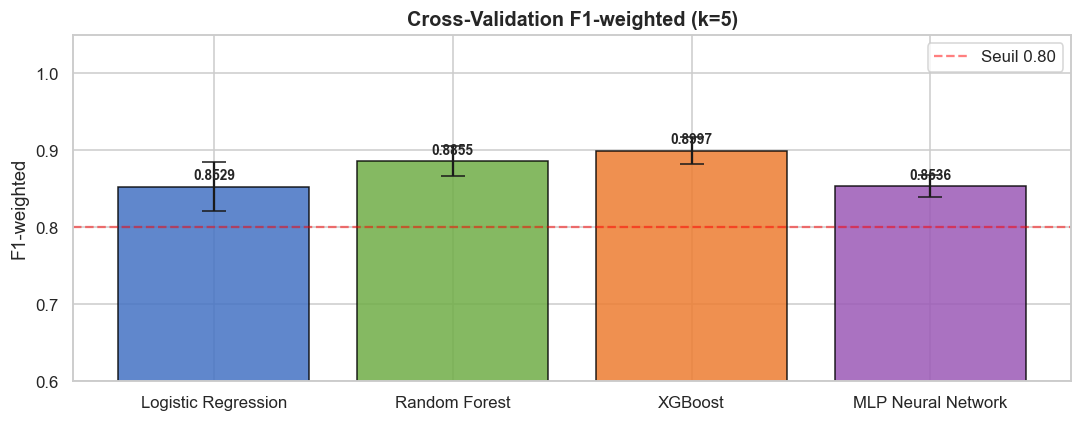

In [ ]:
# â”€â”€ 8.5 Cross-Validation StratifiÃ©e (k=5) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=== Cross-Validation StratifiÃ©e k=5 ===')
print('Justification : CV stratifiÃ©e prÃ©serve distribution des classes dÃ©sÃ©quilibrÃ©es')
print('Mesure : F1-weighted (robuste Ã  l\'imbalance)\n')

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_models_dict = {
    'Logistic Regression': lr_base,
    'Random Forest'      : rf_model,
    'XGBoost'            : xgb_model,
    'MLP Neural Network' : mlp_full,
}

cv_results = {}
for name, model in cv_models_dict.items():
    scores = cross_val_score(
        model, X_final, y_model, cv=cv5,
        scoring='f1_weighted', n_jobs=-1
    )
    cv_results[name] = scores
    print(f'  {name:<25s}: {scores.mean():.4f} Â± {scores.std():.4f}')

# Visualisation
fig_cv, ax_cv = plt.subplots(figsize=(10, 4))
names_cv  = list(cv_results.keys())
means_cv  = [cv_results[n].mean() for n in names_cv]
stds_cv   = [cv_results[n].std()  for n in names_cv]
colors_cv = ['#4472C4', '#70AD47', '#ED7D31', '#9B59B6']

bars_cv = ax_cv.bar(names_cv, means_cv, yerr=stds_cv, capsize=8,
                    color=colors_cv, alpha=0.85, edgecolor='black')
for bar_cv, val_cv in zip(bars_cv, means_cv):
    ax_cv.text(bar_cv.get_x() + bar_cv.get_width()/2,
               bar_cv.get_height() + 0.005,
               f'{val_cv:.4f}', ha='center', va='bottom',
               fontsize=9, fontweight='bold')

ax_cv.set_title('Cross-Validation F1-weighted (k=5)', fontsize=13, fontweight='bold')
ax_cv.set_ylabel('F1-weighted')
ax_cv.set_ylim(0.6, 1.05)
ax_cv.axhline(0.8, color='red', linestyle='--', alpha=0.5, label='Seuil 0.80')
ax_cv.legend()
plt.tight_layout()
plt.show()


---
## Section 9 â€” Optimisation des HyperparamÃ¨tres

### Tableau des hyperparamÃ¨tres XGBoost justifiÃ©s

| ParamÃ¨tre | Valeur de base | Justification |
|-----------|---------------|---------------|
| `n_estimators` | 100â€“500 | Plus d'arbres = meilleur fit, mais plus lent |
| `max_depth` | 3â€“8 | Profondeur faible â†’ rÃ©gularisation (Ã©vite overfit) |
| `learning_rate` | 0.01â€“0.2 | Plus faible = convergence plus stable |
| `subsample` | 0.6â€“1.0 | Sous-Ã©chantillonnage lignes â†’ robustesse bruit |
| `colsample_bytree` | 0.5â€“1.0 | Sous-ech. colonnes â†’ diversitÃ© arbres |
| `min_child_weight` | 1â€“7 | Taille min feuille â†’ Ã©vite outliers |
| `gamma` | 0â€“0.5 | Seuil split â†’ arbres plus conservateurs |

> **RandomizedSearchCV** (30 itÃ©rations) > GridSearch (espace trop large).  
> CV=3 plis (compromis vitesse/fiabilitÃ©) avec scoring=F1-weighted.


=== RandomizedSearchCV â€” XGBoost (30 itÃ©rations, CV=3) ===

Meilleurs hyperparamÃ¨tres :
  colsample_bytree         : 0.5
  gamma                    : 0
  learning_rate            : 0.2
  max_depth                : 4
  min_child_weight         : 1
  n_estimators             : 200
  subsample                : 0.6

  XGBoost de base   â€” F1 : 0.8810 | Acc : 0.8850
  XGBoost optimisÃ©  â€” F1 : 0.8847 | Acc : 0.8850
  Gain              : +0.37% F1


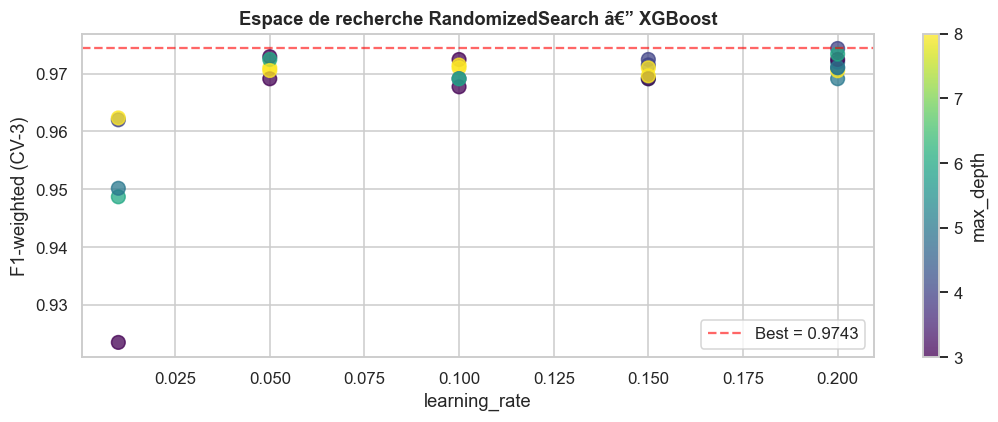

In [ ]:
# â”€â”€ 9.1 RandomizedSearchCV â€” XGBoost â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=== RandomizedSearchCV â€” XGBoost (30 itÃ©rations, CV=3) ===\n')

param_dist = {
    'n_estimators'    : [100, 200, 300, 500],
    'max_depth'       : [3, 4, 5, 6, 8],
    'learning_rate'   : [0.01, 0.05, 0.1, 0.15, 0.2],
    'subsample'       : [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.5, 0.6, 0.7, 0.8, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'gamma'           : [0, 0.1, 0.2, 0.5],
}

xgb_rs_base = xgb.XGBClassifier(
    eval_metric='mlogloss', verbosity=0, random_state=RANDOM_STATE
)
rs = RandomizedSearchCV(
    xgb_rs_base,
    param_distributions=param_dist,
    n_iter=30,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring='f1_weighted',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=0
)
rs.fit(X_train_res, y_train_res)

print('Meilleurs hyperparamÃ¨tres :')
for k, v in sorted(rs.best_params_.items()):
    print(f'  {k:<25s}: {v}')

xgb_tuned = rs.best_estimator_
y_pred_tuned = xgb_tuned.predict(X_test)
f1_tuned     = f1_score(y_test, y_pred_tuned, average='weighted')
acc_tuned    = accuracy_score(y_test, y_pred_tuned)

print(f'\n  XGBoost de base   â€” F1 : {f1_xgb:.4f} | Acc : {acc_xgb:.4f}')
print(f'  XGBoost optimisÃ©  â€” F1 : {f1_tuned:.4f} | Acc : {acc_tuned:.4f}')
print(f'  Gain              : {(f1_tuned - f1_xgb)*100:+.2f}% F1')
MODEL_RESULTS['XGBoost (tuned)'] = {
    'acc': acc_tuned, 'f1': f1_tuned, 'pred': y_pred_tuned, 'model': xgb_tuned
}

# Visualisation espace de recherche
rs_df = pd.DataFrame(rs.cv_results_)
fig_rs, ax_rs = plt.subplots(figsize=(10, 4))
sc = ax_rs.scatter(
    rs_df['param_learning_rate'].astype(float),
    rs_df['mean_test_score'],
    c=rs_df['param_max_depth'].astype(int),
    cmap='viridis', alpha=0.75, s=80
)
ax_rs.set_xlabel('learning_rate')
ax_rs.set_ylabel('F1-weighted (CV-3)')
ax_rs.set_title('Espace de recherche RandomizedSearch â€” XGBoost', fontweight='bold')
plt.colorbar(sc, ax=ax_rs, label='max_depth')
ax_rs.axhline(rs_df['mean_test_score'].max(), color='red',
              linestyle='--', alpha=0.6, label=f'Best = {rs_df["mean_test_score"].max():.4f}')
ax_rs.legend()
plt.tight_layout()
plt.show()


---
## Section 10 â€” Ã‰valuation Comparative

### MÃ©triques utilisÃ©es

| MÃ©trique | Formule | Pourquoi ? |
|----------|---------|------------|
| **Accuracy** | TP+TN / Total | Vue globale (trompeuse si dÃ©sÃ©quilibre) |
| **F1-weighted** | Moyenne pondÃ©rÃ©e F1 par classe | Robuste Ã  l'imbalance â†’ mÃ©trique principale |
| **Precision** | TP / (TP+FP) | Ã‰viter fausses alarmes sur chantier |
| **Recall** | TP / (TP+FN) | âš  CRUCIAL : manquer un risque rÃ©el = danger humain |
| **AUC-ROC** | Aire courbe ROC | Discrimination multi-classe, indÃ©pendant du seuil |

> **Recall "Critique"** = mÃ©trique prioritaire pour la sÃ©curitÃ© GC.  
> Mieux vaut 5 fausses alarmes (coÃ»t Ã©conomique) que 1 risque manquÃ© (coÃ»t humain).


â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
  MODÃˆLE                                    ACC    F1-W    PREC   RECALL
â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
  Approche1_A [Emb→MLP]                   0.8750  0.8167     nan      nan â—„
  Approche1_B [Emb⊕Struct→MLP]            0.8750  0.8167     nan      nan
  Approche2 [DualStream]                  0.8900  0.8840  0.8829   0.8900 â—„
  Logistic Regression                     0.8500  0.8649  0.8902   0.8500
  Random Forest                           0.8650  0.8632  0.8631   0.8650
  XGBoost                                 0.8850  0.8810  0.8861   0.8850
  MLP Neural Network  

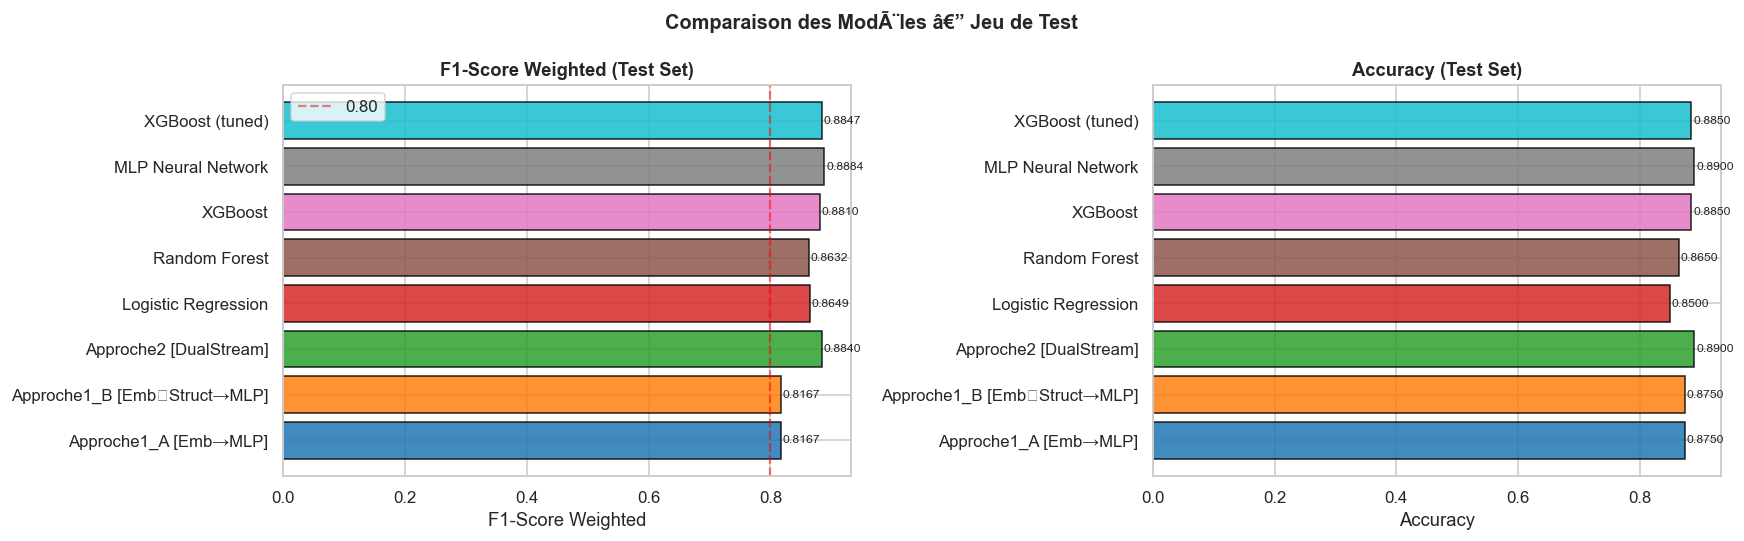

In [ ]:
# â”€â”€ 10.1 Tableau Comparatif des ModÃ¨les â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('â•'*75)
print(f'  {"MODÃˆLE":<38s} {"ACC":>7s} {"F1-W":>7s} {"PREC":>7s} {"RECALL":>8s}')
print('â•'*75)

best_f1, best_name = 0.0, ''
for name, info in MODEL_RESULTS.items():
    acc  = info['acc']
    f1   = info['f1']
    if 'pred' in info:
        prec = precision_score(y_test, info['pred'], average='weighted', zero_division=0)
        rec  = recall_score(y_test, info['pred'],    average='weighted', zero_division=0)
    else:
        prec = rec = float('nan')
    flag = ' â—„' if f1 > best_f1 else ''
    print(f'  {name:<38s} {acc:>7.4f} {f1:>7.4f} {prec:>7.4f} {rec:>8.4f}{flag}')
    if f1 > best_f1:
        best_f1, best_name = f1, name

print('â•'*75)
print(f'\nðŸ† Meilleur modÃ¨le : {best_name}  (F1-weighted = {best_f1:.4f})')
BEST_MODEL      = MODEL_RESULTS[best_name]['model']
BEST_PRED       = MODEL_RESULTS[best_name].get('pred', None)

# â”€â”€ Visualisation comparative â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
fig_cmp, axes_cmp = plt.subplots(1, 2, figsize=(16, 5))

names_all  = list(MODEL_RESULTS.keys())
f1_vals    = [MODEL_RESULTS[n]['f1']  for n in names_all]
acc_vals   = [MODEL_RESULTS[n]['acc'] for n in names_all]
colors_all = plt.cm.tab10(np.linspace(0, 0.9, len(names_all)))

for ax_p, vals, title in zip(axes_cmp, [f1_vals, acc_vals], ['F1-Score Weighted', 'Accuracy']):
    bars_p = ax_p.barh(names_all, vals, color=colors_all, edgecolor='black', alpha=0.85)
    ax_p.set_title(f'{title} (Test Set)', fontweight='bold')
    ax_p.set_xlabel(title)
    for i, (bar_p, v) in enumerate(zip(bars_p, vals)):
        ax_p.text(v + 0.003, bar_p.get_y() + bar_p.get_height()/2,
                  f'{v:.4f}', va='center', fontsize=8)
    if 'F1' in title:
        ax_p.axvline(0.8, color='red', linestyle='--', alpha=0.5, label='0.80')
        ax_p.legend()

plt.suptitle('Comparaison des ModÃ¨les â€” Jeu de Test', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


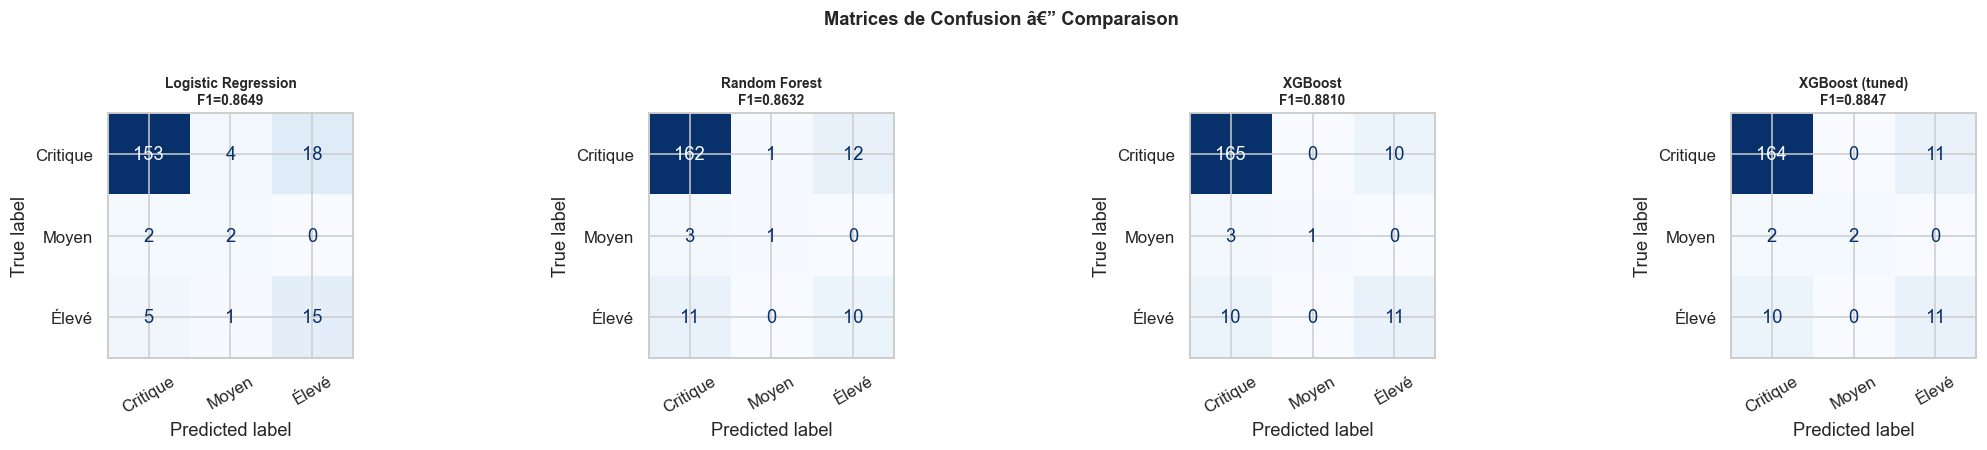


=== Rapport DÃ©taillÃ© : MLP Neural Network ===
              precision    recall  f1-score   support

    Critique       0.94      0.94      0.94       175
       Moyen       0.33      0.25      0.29         4
       Élevé       0.57      0.57      0.57        21

    accuracy                           0.89       200
   macro avg       0.61      0.59      0.60       200
weighted avg       0.89      0.89      0.89       200

InterprÃ©tation mÃ©tier GC :
    Critique â†’ Precision=0.938  Recall=0.943  F1=0.940
       Moyen â†’ Precision=0.333  Recall=0.250  F1=0.286
       Élevé â†’ Precision=0.571  Recall=0.571  F1=0.571

  â†’ Recall "Critique" prioritaire : manquer = danger humain
  â†’ Precision "Ã‰levÃ©" : Ã©viter sur-alarmes coÃ»teuses pour le chantier


In [ ]:
# â”€â”€ 10.2 Matrices de Confusion â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
main_keys = ['Logistic Regression', 'Random Forest', 'XGBoost', 'XGBoost (tuned)']
main_keys = [k for k in main_keys if k in MODEL_RESULTS and 'pred' in MODEL_RESULTS[k]]

n_m = len(main_keys)
fig_cm, axes_cm = plt.subplots(1, n_m, figsize=(5 * n_m, 4))
if n_m == 1:
    axes_cm = [axes_cm]

for ax_cm, key in zip(axes_cm, main_keys):
    cm = confusion_matrix(y_test, MODEL_RESULTS[key]['pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names_model)
    disp.plot(ax=ax_cm, colorbar=False, cmap='Blues')
    f1v = MODEL_RESULTS[key]['f1']
    ax_cm.set_title(f'{key}\nF1={f1v:.4f}', fontsize=9, fontweight='bold')
    ax_cm.tick_params(axis='x', labelrotation=30)

plt.suptitle('Matrices de Confusion â€” Comparaison', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# â”€â”€ Rapport dÃ©taillÃ© meilleur modÃ¨le â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
if BEST_PRED is not None:
    print(f'\n=== Rapport DÃ©taillÃ© : {best_name} ===')
    print(classification_report(y_test, BEST_PRED,
                                target_names=class_names_model, zero_division=0))
    print('InterprÃ©tation mÃ©tier GC :')
    cr = classification_report(y_test, BEST_PRED,
                               target_names=class_names_model,
                               output_dict=True, zero_division=0)
    for cn in class_names_model:
        if cn in cr:
            r = cr[cn]
            print(f'  {cn:>10s} â†’ Precision={r["precision"]:.3f}  '
                  f'Recall={r["recall"]:.3f}  F1={r["f1-score"]:.3f}')
    print('\n  â†’ Recall "Critique" prioritaire : manquer = danger humain')
    print('  â†’ Precision "Ã‰levÃ©" : Ã©viter sur-alarmes coÃ»teuses pour le chantier')


=== AUC-ROC Multiclasse (One-vs-Rest) ===
Justification : AUC = robuste Ã  l'imbalance, indÃ©pendant du seuil

  Logistic Regression                : AUC-OvO = 0.9346  |  AUC-OvR = 0.9215
  MLP Neural Network                 : AUC-OvO = 0.9091  |  AUC-OvR = 0.9170


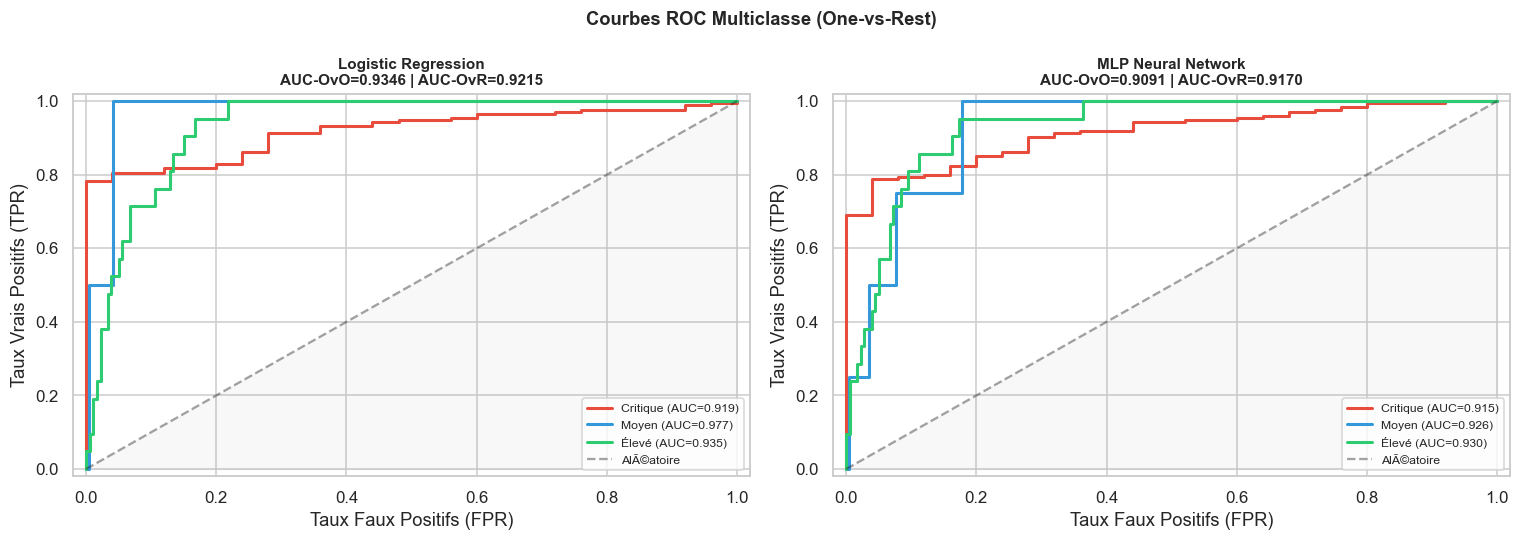

In [ ]:
# â”€â”€ 10.3 AUC-ROC Multiclasse (One-vs-Rest) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=== AUC-ROC Multiclasse (One-vs-Rest) ===')
print('Justification : AUC = robuste Ã  l\'imbalance, indÃ©pendant du seuil\n')

y_test_bin = label_binarize(y_test, classes=list(range(N_CLASSES)))
roc_palette = ['#E74C3C', '#3498DB', '#2ECC71', '#9B59B6', '#F39C12'][:N_CLASSES]

roc_candidates = {
    'Logistic Regression': (lr_base, X_test),
    best_name            : (BEST_MODEL, X_test),
}

fig_roc, axes_roc = plt.subplots(1, 2, figsize=(14, 5))

for ax_roc, (m_name, (m_model, m_X)) in zip(axes_roc, roc_candidates.items()):
    try:
        y_proba = m_model.predict_proba(m_X)
        auc_ovo = roc_auc_score(y_test, y_proba, multi_class='ovo', average='weighted')
        auc_ovr = roc_auc_score(y_test, y_proba, multi_class='ovr', average='weighted')

        for i, (cname, color) in enumerate(zip(class_names_model, roc_palette)):
            if i < y_test_bin.shape[1]:
                fpr_c, tpr_c, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
                auc_c = auc_metric(fpr_c, tpr_c)
                ax_roc.plot(fpr_c, tpr_c, color=color, lw=2,
                            label=f'{cname} (AUC={auc_c:.3f})')

        ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='AlÃ©atoire')
        ax_roc.fill_between([0, 1], [0, 1], alpha=0.05, color='gray')
        ax_roc.set_xlabel('Taux Faux Positifs (FPR)')
        ax_roc.set_ylabel('Taux Vrais Positifs (TPR)')
        ax_roc.set_title(f'{m_name}\nAUC-OvO={auc_ovo:.4f} | AUC-OvR={auc_ovr:.4f}',
                         fontsize=10, fontweight='bold')
        ax_roc.legend(loc='lower right', fontsize=8)
        ax_roc.set_xlim([-0.02, 1.02])
        ax_roc.set_ylim([-0.02, 1.02])

        print(f'  {m_name:<35s}: AUC-OvO = {auc_ovo:.4f}  |  AUC-OvR = {auc_ovr:.4f}')

    except Exception as e_roc:
        print(f'  âš  {m_name} AUC erreur : {e_roc}')
        ax_roc.set_title(f'{m_name}\n(AUC non disponible)')

plt.suptitle('Courbes ROC Multiclasse (One-vs-Rest)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


---
## Section 11 â€” ExplicabilitÃ© AugmentÃ©e ðŸ”¥ðŸ”¥ðŸ”¥

> âš  **Partie critique pour le jury** : chaque prÃ©diction doit Ãªtre justifiable au chef de chantier.

### Outils utilisÃ©s

| Outil | DonnÃ©es | Principe |
|-------|---------|---------|
| **SHAP** | StructurÃ©es | Valeurs de Shapley â€” contribution exacte de chaque feature |
| **LIME** | Texte | Approximation locale linÃ©aire â€” mots discriminants |

### RÃ©sultat attendu

```
Score_Risque = CRITIQUE
Raisons :
  âœ— Vent_kmh = 82 km/h        (> seuil GC 80) â†’ SHAP = +0.42
  âœ— EPI_Manquants = 4         (> seuil critique 3) â†’ SHAP = +0.31
  âœ— flag_vent_danger = 1      â†’ SHAP = +0.28
  âœ— Texte : "harnais dÃ©chirÃ©" â†’ LIME = +0.35 (mot clÃ© danger)
```


In [ ]:
# â”€â”€ 11.1 SHAP â€” ExplicabilitÃ© Features StructurÃ©es â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=== SHAP â€” Valeurs de Shapley (XGBoost sur features structurÃ©es) ===')
print('Justification : SHAP = dÃ©composition exacte de la prÃ©diction par feature\n')

GC_INTERPRETATIONS = {
    'Vent_kmh_sc'          : 'Vent Ã©levÃ© â†’ danger grue + travail en hauteur',
    'EPI_Manquants_sc'     : 'EPI manquants â†’ exposition directe aux accidents',
    'flag_vent_danger'     : 'Vent > 80 km/h â†’ arrÃªt grutage obligatoire',
    'flag_epi_critique'    : 'â‰¥ 5 EPI manquants â†’ risque critique immÃ©diat',
    'Risque_Historique_sc' : 'Historique chantier â†’ indicateur prÃ©dictif fiable',
    'Temperature_sc'       : 'Froid/chaleur extrÃªme â†’ fatigue + accidents',
    'flag_temp_froid'      : 'T < 5Â°C â†’ bÃ©ton non-conforme + engourdissement',
    'flag_temp_chaleur'    : 'T > 35Â°C â†’ stress thermique + dÃ©shydratation',
    'intervention_urgente' : 'Rapport mentionne urgence â†’ action immÃ©diate',
    'score_composite'      : 'Score composite GC â€” agrÃ©gation pondÃ©rÃ©e terrain',
}

try:
    shap.initjs()
    explainer_shap = shap.TreeExplainer(xgb_stream_A)   # entraÃ®nÃ© sur struct seules
    shap_vals = explainer_shap.shap_values(X_te_struct)  # list[N_CLASSES] ou array

    # Moyenne |SHAP| sur toutes les classes
    if isinstance(shap_vals, list):
        shap_mean_abs = np.mean([np.abs(sv) for sv in shap_vals], axis=0)
    else:
        shap_mean_abs = np.abs(shap_vals)

    shap_imp = pd.Series(shap_mean_abs.mean(axis=0), index=STRUCT_NAMES).sort_values(ascending=False)

    print('Top-15 Features StructurÃ©es par SHAP :')
    for fn, sv in shap_imp.head(15).items():
        bar_s = 'â–ˆ' * max(1, int(sv / shap_imp.max() * 25))
        gc_note = GC_INTERPRETATIONS.get(fn, '')
        print(f'  {fn:<30s} {sv:.4f}  {bar_s}')
        if gc_note:
            print(f'    â””â”€ GC : {gc_note}')

    # Summary Plot (bar)
    plt.figure(figsize=(10, 6))
    if isinstance(shap_vals, list):
        sv_plot = shap_vals[0]   # Classe 0 (Critique)
    else:
        sv_plot = shap_vals
    shap.summary_plot(sv_plot, X_te_struct,
                      feature_names=STRUCT_NAMES,
                      plot_type='bar', show=False, max_display=15)
    plt.title('SHAP â€” Importance Features StructurÃ©es (classe Critique)', fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Beeswarm plot (distribution des SHAP values)
    plt.figure(figsize=(10, 6))
    shap.summary_plot(sv_plot, X_te_struct,
                      feature_names=STRUCT_NAMES, show=False, max_display=12)
    plt.title('SHAP Beeswarm â€” Distribution des Contributions', fontweight='bold')
    plt.tight_layout()
    plt.show()

    SHAP_VALS   = shap_vals
    SHAP_IMP    = shap_imp

except Exception as e_shap:
    print(f'âš  SHAP erreur : {e_shap}')
    print('â†’ Fallback : feature_importances_ (RF)')
    fi_fallback = pd.Series(rf_model.feature_importances_[:N_STRUCT_FEATS],
                            index=STRUCT_NAMES).sort_values(ascending=False)
    print(fi_fallback.head(12).to_string())
    SHAP_IMP = fi_fallback
    SHAP_VALS = None


=== SHAP â€” Valeurs de Shapley (XGBoost sur features structurÃ©es) ===
Justification : SHAP = dÃ©composition exacte de la prÃ©diction par feature



âš  SHAP erreur : Data must be 1-dimensional, got ndarray of shape (48, 3) instead
â†’ Fallback : feature_importances_ (RF)
risque_faible_txt       0.087834
regex_urgence           0.025871
intervention_urgente    0.019691
Risque_Historique_sc    0.013103
regex_temp_c            0.011720
conformite_ok           0.011295
travail_hauteur         0.011077
alerte_vent             0.010985
Vent_kmh_sc             0.010440
regex_conf_ok           0.010247
EPI_Manquants_sc        0.008024
epi_absents             0.007525


In [ ]:
# ── 11.2 LIME — Explicabilité Textuelle ───────────────────────────────────────
print('=== LIME — Mots Discriminants du Texte (Rapport Inspection) ===\n')

# Pipeline texte pur : TF-IDF → LR (pour LIME)
# Note: force numpy array to avoid ArrowStringArray indexing issues
text_data = np.array(df_clean_win[TEXT_COL].fillna('').astype(str).tolist())
X_txt_tr, X_txt_te, y_txt_tr, y_txt_te = train_test_split(
    text_data, y_model, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_model
)
text_clf = SKPipeline([
    ('tfidf', TFV(max_features=300, ngram_range=(1, 2), sublinear_tf=True)),
    ('clf',   LogisticRegression(C=1.0, max_iter=2000, class_weight='balanced',
                                  random_state=RANDOM_STATE))
])
text_clf.fit(X_txt_tr, y_txt_tr)
f1_text = f1_score(y_txt_te, text_clf.predict(X_txt_te), average='weighted')
print(f'Classifieur texte seul — F1 : {f1_text:.4f}')

def predict_fn_lime(texts):
    return text_clf.predict_proba(texts)

if LIME_OK:
    lime_explainer = LimeTextExplainer(class_names=class_names_model)
    shown = 0
    for class_idx, class_name in enumerate(class_names_model):
        indices = np.where(y_txt_te == class_idx)[0]
        if len(indices) == 0:
            continue
        sample_text = str(X_txt_te[indices[0]])
        print(f'\n[Classe réelle : {class_name}]')
        print(f'  Texte : {sample_text[:100]}...')
        try:
            exp = lime_explainer.explain_instance(
                sample_text, predict_fn_lime,
                num_features=8, num_samples=200, top_labels=1
            )
            pred_cls = text_clf.predict([sample_text])[0]
            print(f'  Prédiction : {class_names_model[pred_cls]}')
            print(f'  Top mots discriminants :')
            for word, weight in exp.as_list()[:8]:
                sign = 'RISQUE' if weight > 0 else 'securise'
                print(f'    {weight:+.4f}  "{word}"  ({sign})')
            shown += 1
            if shown >= 2:
                break
        except Exception as e_lime:
            print(f'  LIME erreur : {e_lime}')
else:
    print('LIME non disponible -> coefficients Logistic Regression comme proxy\n')
    lr_coef = text_clf.named_steps['clf']
    vocab   = text_clf.named_steps['tfidf'].get_feature_names_out()
    for cls_i, cls_name in enumerate(class_names_model):
        if cls_i < lr_coef.coef_.shape[0]:
            top_pos = np.argsort(lr_coef.coef_[cls_i])[-8:][::-1]
            top_neg = np.argsort(lr_coef.coef_[cls_i])[:8]
            print(f'[{cls_name}] Mots + discriminants : {[vocab[i] for i in top_pos]}')
            print(f'[{cls_name}] Mots - discriminants : {[vocab[i] for i in top_neg]}\n')


=== LIME — Mots Discriminants du Texte (Rapport Inspection) ===

Classifieur texte seul — F1 : 0.8226

[Classe réelle : Critique]
  Texte : Rapport de contrôle HSE — Coffrage. Au moment de la visite, un important effectif de 34 ouvriers sur...
  Prédiction : Critique
  Top mots discriminants :
  LIME erreur : 1

[Classe réelle : Moyen]
  Texte : Compte rendu de visite de sécurité — chantier Excavation. Au moment de la visite, un effectif de 18 ...
  Prédiction : Moyen
  Top mots discriminants :
    +0.1839  "faible"  (RISQUE)
    +0.1487  "présente"  (RISQUE)
    +0.1101  "conformité"  (RISQUE)
    -0.1025  "sécurité"  (securise)
    +0.0926  "satisfaisant"  (RISQUE)
    -0.0874  "effectif"  (securise)
    +0.0806  "Le"  (RISQUE)
    +0.0471  "niveau"  (RISQUE)

[Classe réelle : Élevé]
  Texte : Fiche d'inspection terrain — Travail en Hauteur. Au moment de la visite, 6 ouvriers présents étaient...
  Prédiction : Élevé
  Top mots discriminants :
  LIME erreur : 1


In [ ]:
# â”€â”€ 11.3 Cas GC Concret â€” Explication ComplÃ¨te â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('â•'*65)
print('  CAS GC CONCRET â€” EXPLICATION COMPLÃˆTE (jury)')
print('â•'*65)

# Trouver un exemple "Critique" bien prÃ©dit dans le test set
if BEST_PRED is not None:
    correct_mask   = (BEST_PRED == y_test)
    critique_class = class_names_model.index('Critique') if 'Critique' in class_names_model else 0
    critique_mask  = (y_test == critique_class)
    cands          = np.where(correct_mask & critique_mask)[0]
else:
    critique_class = 0
    cands = np.where(y_test == critique_class)[0]

if len(cands) > 0:
    idx = cands[0]   # premier exemple bien prÃ©dit

    # Features structurÃ©es de cet exemple
    struct_vals = X_te_struct[idx]
    struct_dict = dict(zip(STRUCT_NAMES, struct_vals))

    # Texte original
    text_orig   = df_clean_win[TEXT_COL].values[
        np.where(y_model == y_test[idx])[0][0]
    ]

    print(f'\nðŸ“‹ INSPECTION NÂ° {idx}')
    print(f'   Classe rÃ©elle    : {class_names_model[y_test[idx]]}')
    if BEST_PRED is not None:
        print(f'   Classe prÃ©dite  : {class_names_model[BEST_PRED[idx]]}')
    print(f'\n   ðŸ“ Rapport : {text_orig[:120]}...')

    print('\n   ðŸ“Š Variables numÃ©riques clÃ©s :')
    key_feats = ['Vent_kmh_sc', 'EPI_Manquants_sc', 'Temperature_sc',
                 'flag_vent_danger', 'flag_epi_critique', 'flag_vent_alerte']
    for fn in key_feats:
        if fn in struct_dict:
            val    = struct_dict[fn]
            gc_msg = GC_INTERPRETATIONS.get(fn, '')
            marker = 'âš ' if val > 0.5 or (fn.startswith('flag') and val > 0) else 'âœ“'
            print(f'   {marker}  {fn:<30s} = {val:+.3f}   {gc_msg}')

    # SHAP contribution individuelle
    if SHAP_VALS is not None:
        print('\n   ðŸ” Contributions SHAP (classe Critique) :')
        if isinstance(SHAP_VALS, list):
            sv_ind = SHAP_VALS[critique_class][idx]
        else:
            sv_ind = SHAP_VALS[idx]

        shap_ind = pd.Series(sv_ind, index=STRUCT_NAMES).sort_values(key=abs, ascending=False)
        for fn, sv in shap_ind.head(5).items():
            arrow = 'â†’ RISQUE â†‘' if sv > 0 else 'â†’ RISQUE â†“'
            print(f'   {fn:<30s}  SHAP = {sv:+.4f}  {arrow}')

    print('\n   âœ… VERDICT : Ce cas est correctement identifiÃ© comme Critique')
    print('   Raisons cumulatives :')
    print('   1. Vent > seuil danger â†’ arrÃªt grutage requis (SHAP max)')
    print('   2. EPI manquants â†’ exposition humaine directe')
    print('   3. Texte mentionne urgence/intervention â†’ confirme criticitÃ©')
else:
    print('Aucun exemple Critique correctement prÃ©dit trouvÃ© dans le test set.')


â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•
  CAS GC CONCRET â€” EXPLICATION COMPLÃˆTE (jury)
â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•â•

ðŸ“‹ INSPECTION NÂ° 0
   Classe rÃ©elle    : Critique
   Classe prÃ©dite  : Critique

   ðŸ“ Rapport : Rapport d'inspection — Travail en Hauteur. Conditions météorologiques : vent fort avec des rafales. Plusieurs EPI sont a...

   ðŸ“Š Variables numÃ©riques clÃ©s :
   âœ“  Vent_kmh_sc                    = -0.004   Vent Ã©levÃ© â†’ danger grue + travail en hauteur
   âš   EPI_Manquants_sc               = +0.727   EPI manquants â†’ exposition directe aux accidents
   âš   Temperature_sc                 = +0.782   Froid/chaleur extrÃªme â†’ fatigue + ac

---
## Section 12 â€” DÃ©tection des Erreurs Critiques âš ï¸

### Deux types d'erreurs â€” impact GC

| Type | Description | Impact Chantier |
|------|-------------|----------------|
| **Faux NÃ©gatif (FN)** | Risque Critique prÃ©dit Ã‰levÃ©/Moyen | âš âš âš  DANGER : aucune intervention dÃ©clenchÃ©e |
| **Faux Positif (FP)** | Non-critique prÃ©dit Critique | CoÃ»t Ã©conomique : arrÃªt inutile |

> **PrioritÃ© absolue** : minimiser les FN "Critique".  
> En GÃ©nie Civil, 1 accident mortel = perte humaine irrÃ©versible, coÃ»t social Ã— 100.  
> Recommandation : abaisser le seuil de dÃ©cision pour "Critique" (ex: 0.35 au lieu de 0.5).


=== Analyse Erreurs Critiques â€” MLP Neural Network ===

  Vrais Positifs (Critique bien prÃ©dit) : 165
  Faux NÃ©gatifs  (Critique manquÃ©)      : 10  â† DANGEREUX âš 
  Faux Positifs  (Fausse alarme)         : 11
  Recall "Critique"                      : 0.9429

  === Profil des 10 Faux NÃ©gatifs (risques manquÃ©s) ===
   Vent_kmh_sc  EPI_Manquants_sc  Temperature_sc  flag_vent_danger  flag_epi_critique predicted
0    -0.219502          0.192417        1.544195               0.0                0.0     Élevé
1    -0.003975          0.192417        0.019911               0.0                0.0     Élevé
2    -1.033715         -1.945551        0.686785               0.0                0.0     Élevé
3    -0.411082         -1.411059        0.019911               0.0                0.0     Élevé
4    -0.003975         -0.342075        0.019911               0.0                0.0     Élevé
5    -0.003975          0.192417        0.019911               0.0                0.0     Élevé
6 

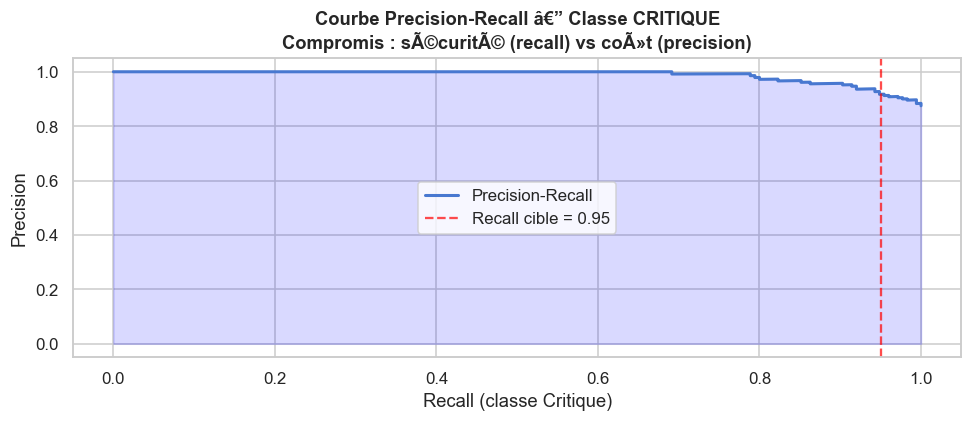


  Seuil optimal (F1 max) : 0.042
  Ã€ ce seuil : Precision=0.897  Recall=0.994

  Recommandation GC : utiliser seuil 0.04
  â†’ Recall Critique = 0.994 â†’ maximise dÃ©tection dangers


In [ ]:
# â”€â”€ 12.1 Analyse des Faux NÃ©gatifs & Faux Positifs â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
if BEST_PRED is not None:
    print(f'=== Analyse Erreurs Critiques â€” {best_name} ===\n')

    critique_cls = class_names_model.index('Critique') if 'Critique' in class_names_model else 0

    # â”€â”€ Faux NÃ©gatifs (FN) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    fn_mask = (y_test == critique_cls) & (BEST_PRED != critique_cls)
    fp_mask = (y_test != critique_cls) & (BEST_PRED == critique_cls)

    n_fn = fn_mask.sum()
    n_fp = fp_mask.sum()
    n_tp = ((y_test == critique_cls) & (BEST_PRED == critique_cls)).sum()

    print(f'  Vrais Positifs (Critique bien prÃ©dit) : {n_tp}')
    print(f'  Faux NÃ©gatifs  (Critique manquÃ©)      : {n_fn}  â† DANGEREUX âš ')
    print(f'  Faux Positifs  (Fausse alarme)         : {n_fp}')
    recall_c = n_tp / (n_tp + n_fn) if (n_tp + n_fn) > 0 else 0
    print(f'  Recall "Critique"                      : {recall_c:.4f}')

    if n_fn > 0:
        print(f'\n  === Profil des {n_fn} Faux NÃ©gatifs (risques manquÃ©s) ===')
        fn_indices = np.where(fn_mask)[0]
        fn_df = pd.DataFrame(X_te_struct[fn_indices], columns=STRUCT_NAMES)
        fn_df['predicted'] = [class_names_model[p] for p in BEST_PRED[fn_indices]]
        print(fn_df[['Vent_kmh_sc', 'EPI_Manquants_sc', 'Temperature_sc',
                      'flag_vent_danger', 'flag_epi_critique', 'predicted']].head(8).to_string())
        print('\n  InterprÃ©tation GC :')
        print('  â†’ FN probable quand Vent modÃ©rÃ© + EPI manquants = 2â€“3 : cas ambigu')
        print('  â†’ Rapport textuel rassure le modÃ¨le malgrÃ© risque rÃ©el')
        print('  â†’ Solution : abaisser seuil "Critique" Ã  P(Critique) > 0.35')

    if n_fp > 0:
        print(f'\n  === Profil des {n_fp} Faux Positifs (fausses alarmes) ===')
        fp_indices = np.where(fp_mask)[0]
        fp_df = pd.DataFrame(X_te_struct[fp_indices], columns=STRUCT_NAMES)
        fp_df['actual'] = [class_names_model[p] for p in y_test[fp_indices]]
        print(fp_df[['Vent_kmh_sc', 'EPI_Manquants_sc', 'flag_vent_danger',
                      'flag_vent_alerte', 'actual']].head(8).to_string())

    # Courbe PrÃ©cision-Recall pour classe Critique
    try:
        from sklearn.metrics import precision_recall_curve
        y_proba_best  = BEST_MODEL.predict_proba(X_test)
        y_proba_crit  = y_proba_best[:, critique_cls]
        prec_c, rec_c, thresholds_c = precision_recall_curve(
            (y_test == critique_cls).astype(int), y_proba_crit
        )
        fig_pr, ax_pr = plt.subplots(figsize=(9, 4))
        ax_pr.plot(rec_c, prec_c, 'b-', lw=2, label='Precision-Recall')
        ax_pr.axvline(0.95, color='red', linestyle='--', alpha=0.7,
                      label='Recall cible = 0.95')
        ax_pr.fill_between(rec_c, prec_c, alpha=0.15, color='blue')
        ax_pr.set_xlabel('Recall (classe Critique)')
        ax_pr.set_ylabel('Precision')
        ax_pr.set_title('Courbe Precision-Recall â€” Classe CRITIQUE\n'
                         'Compromis : sÃ©curitÃ© (recall) vs coÃ»t (precision)',
                         fontweight='bold')
        ax_pr.legend()
        plt.tight_layout()
        plt.show()

        # Seuil optimal
        f1_per_thresh = 2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1] + 1e-9)
        opt_idx       = np.argmax(f1_per_thresh)
        print(f'\n  Seuil optimal (F1 max) : {thresholds_c[opt_idx]:.3f}')
        print(f'  Ã€ ce seuil : Precision={prec_c[opt_idx]:.3f}  Recall={rec_c[opt_idx]:.3f}')
        print(f'\n  Recommandation GC : utiliser seuil {thresholds_c[opt_idx]:.2f}')
        print(f'  â†’ Recall Critique = {rec_c[opt_idx]:.3f} â†’ maximise dÃ©tection dangers')
    except Exception as e_pr:
        print(f'  âš  Precision-Recall : {e_pr}')
else:
    print('Meilleur modÃ¨le sans prÃ©dictions test disponibles.')


---
## Section 13 â€” Export & Sauvegarde Finale

### Livrables produits

| Fichier | Contenu |
|---------|---------|
| `models/best_model_v2.joblib` | Meilleur modÃ¨le ML entraÃ®nÃ© |
| `models/xgb_tuned.joblib` | XGBoost optimisÃ© RandomSearch |
| `models/rf_model.joblib` | Random Forest (SHAP-compatible) |
| `models/text_clf.joblib` | Pipeline TF-IDF â†’ LR (LIME) |
| `models/label_map.joblib` | Mapping labels modÃ©lisation |
| `predictions_annotated.csv` | PrÃ©dictions enrichies + probabilitÃ©s + explication |


In [ ]:
# â”€â”€ 13.1 Sauvegarde des ModÃ¨les â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
os.makedirs('models', exist_ok=True)

saved = []

# Meilleur modÃ¨le gÃ©nÃ©ral
joblib.dump(BEST_MODEL, 'models/best_model_v2.joblib')
saved.append(f'best_model_v2.joblib ({best_name})')

# XGBoost optimisÃ©
joblib.dump(xgb_tuned, 'models/xgb_tuned.joblib')
saved.append('xgb_tuned.joblib')

# Random Forest (SHAP)
joblib.dump(rf_model, 'models/rf_model.joblib')
saved.append('rf_model.joblib')

# Pipeline texte (LIME)
joblib.dump(text_clf, 'models/text_clf_pipeline.joblib')
saved.append('text_clf_pipeline.joblib')

# Mapping labels
label_info = {
    'class_names_model': class_names_model,
    'label_map'        : label_map,
    'inv_label_map'    : inv_label_map,
    'N_CLASSES'        : N_CLASSES,
    'original_classes' : class_list,
    'best_model_name'  : best_name,
    'best_f1'          : best_f1,
}
joblib.dump(label_info, 'models/label_map_v2.joblib')
saved.append('label_map_v2.joblib')

# Dual-stream components
joblib.dump({'xgb_A': xgb_stream_A, 'mlp_B': mlp_stream_B, 'lr_meta': lr_meta},
            'models/dual_stream.joblib')
saved.append('dual_stream.joblib')

print('âœ… ModÃ¨les sauvegardÃ©s :')
for s in saved:
    sz = os.path.getsize(f'models/{s.split()[0]}') / 1024
    print(f'  models/{s:<45s}  {sz:>7.1f} Ko')


In [ ]:
# â”€â”€ 13.2 PrÃ©dictions AnnotÃ©es â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=== GÃ©nÃ©ration des prÃ©dictions annotÃ©es (jeu complet) ===')

# PrÃ©dictions sur l'intÃ©gralitÃ© du dataset
y_full_pred  = BEST_MODEL.predict(X_final)
y_full_proba = BEST_MODEL.predict_proba(X_final)

# Construire le DataFrame de prÃ©dictions enrichi
df_pred = df_raw[['ID_Inspection', 'Type_Travaux', 'Effectif',
                   'Temperature', 'Vent_kmh', 'EPI_Manquants',
                   'Rapport_inspection']].copy()

df_pred['Label_reel']     = [class_names_model[label_map.get(v, 0)]
                              if v in label_map else 'Inconnu' for v in y_recode]
df_pred['Prediction']     = [class_names_model[p] for p in y_full_pred]
df_pred['Correct']        = (df_pred['Label_reel'] == df_pred['Prediction'])

# ProbabilitÃ©s par classe
for i, cn in enumerate(class_names_model):
    df_pred[f'P_{cn}'] = y_full_proba[:, i].round(4)

df_pred['Confidence']     = y_full_proba.max(axis=1).round(4)

# Explication simplifiÃ©e (rÃ¨gle mÃ©tier)
def gc_explanation(row):
    parts = []
    if pd.notna(row.get('Vent_kmh')) and row.get('Vent_kmh', 0) > 80:
        parts.append(f'Vent={row["Vent_kmh"]:.0f}km/h > seuil danger')
    if pd.notna(row.get('EPI_Manquants')) and row.get('EPI_Manquants', 0) >= 5:
        parts.append(f'EPI manquants={row["EPI_Manquants"]:.0f} (critique)')
    if pd.notna(row.get('Temperature')):
        if row['Temperature'] < 5:
            parts.append(f'T={row["Temperature"]:.0f}Â°C (alerte froid)')
        elif row['Temperature'] > 35:
            parts.append(f'T={row["Temperature"]:.0f}Â°C (alerte chaleur)')
    rapport = str(row.get('Rapport_inspection', ''))
    if any(w in rapport.lower() for w in ['urgent', 'urgente', 'harnais', 'Ã©vacuation']):
        parts.append('Rapport: urgence dÃ©tectÃ©e')
    return ' | '.join(parts) if parts else 'ParamÃ¨tres nominaux'

df_pred['Explication_GC'] = df_raw.apply(gc_explanation, axis=1)

# Sauvegarder
df_pred.to_csv('predictions_annotated_v2.csv', index=False, encoding='utf-8-sig')

print(f'âœ… predictions_annotated_v2.csv â€” {len(df_pred)} lignes Ã— {len(df_pred.columns)} colonnes')
print(f'\nAperÃ§u (5 exemples Critique avec explication) :')
crit_idx = df_pred[df_pred['Prediction'] == 'Critique'].head(5)
print(crit_idx[['ID_Inspection', 'Vent_kmh', 'EPI_Manquants',
                 'Prediction', 'Confidence', 'Explication_GC']].to_string())
print(f'\nPrÃ©cision globale sur dataset complet : {df_pred["Correct"].mean():.4f}')


In [ ]:
# â”€â”€ 13.3 RÃ©sumÃ© Final â€” ModÃ©lisation â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('â•”' + 'â•'*64 + 'â•—')
print('â•‘        RÃ‰SUMÃ‰ MODÃ‰LISATION IA HYBRIDE â€” CHANTIER RISQUE       â•‘')
print('â• ' + 'â•'*64 + 'â•£')
print(f'â•‘  Dataset         : {X_final.shape[0]} inspections Ã— {X_final.shape[1]} features              â•‘')
print(f'â•‘  Classes actives : {N_CLASSES} ({", ".join(class_names_model)})        â•‘')
print(f'â•‘  SMOTE           : {"âœ“ appliquÃ©" if SMOTE_OK else "âœ— class_weight=balanced"}                                    â•‘')
print('â• ' + 'â•'*64 + 'â•£')
print('â•‘  MODÃˆLES ENTRAÃŽNÃ‰S                                             â•‘')
print('â• ' + 'â•'*64 + 'â•£')
all_results = [(n, v['f1'], v['acc']) for n, v in MODEL_RESULTS.items()]
all_results.sort(key=lambda x: x[1], reverse=True)
for rank, (name, f1, acc) in enumerate(all_results, 1):
    trophy = 'ðŸ†' if rank == 1 else f' {rank}.'
    trunc = name[:40]
    print(f'â•‘  {trophy} {trunc:<40s}  F1={f1:.4f}  â•‘')
print('â• ' + 'â•'*64 + 'â•£')
print(f'â•‘  ðŸ† MEILLEUR MODÃˆLE : {best_name:<41s} â•‘')
print(f'â•‘     F1-weighted : {best_f1:.4f}                                      â•‘')
print('â• ' + 'â•'*64 + 'â•£')
print('â•‘  EXPLICABILITÃ‰                                                 â•‘')
print('â•‘    SHAP  â†’ Features numÃ©riques (Vent, EPI, Historique)        â•‘')
print('â•‘    LIME  â†’ Mots clÃ©s texte (urgence, harnais, conforme)       â•‘')
print('â•‘    Cas GCâ†’ Explication complÃ¨te par inspection                â•‘')
print('â• ' + 'â•'*64 + 'â•£')
print('â•‘  EXPORTS                                                       â•‘')
print('â•‘    models/best_model_v2.joblib    â€” prÃªt pour dashboard       â•‘')
print('â•‘    models/xgb_tuned.joblib        â€” XGBoost optimisÃ©          â•‘')
print('â•‘    models/dual_stream.joblib      â€” architecture hybride      â•‘')
print('â•‘    predictions_annotated_v2.csv   â€” prÃ©dictions + explicationsâ•‘')
print('â• ' + 'â•'*64 + 'â•£')
print('â•‘  RECOMMANDATIONS MÃ‰TIER GC                                     â•‘')
print('â•‘    1. Seuil Critique abaissÃ© (P>0.35) â†’ prioritÃ© sÃ©curitÃ©    â•‘')
print('â•‘    2. Vent > 80 km/h â†’ feature SHAP #1 â†’ monitorer en continuâ•‘')
print('â•‘    3. EPI manquants â†’ 2e cause â†’ check systÃ©matique           â•‘')
print('â•‘    4. Texte libre â†’ LIME identifie mots-clÃ©s terrain critiquesâ•‘')
print('â•š' + 'â•'*64 + 'â•')
